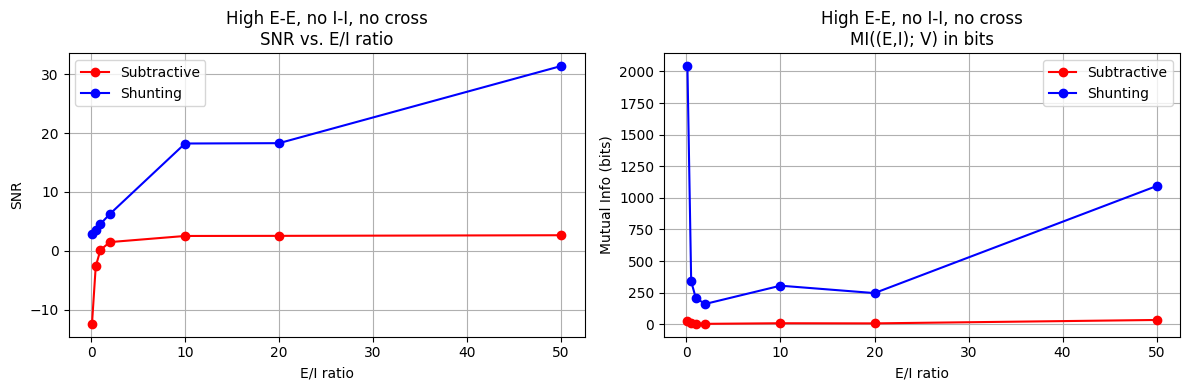

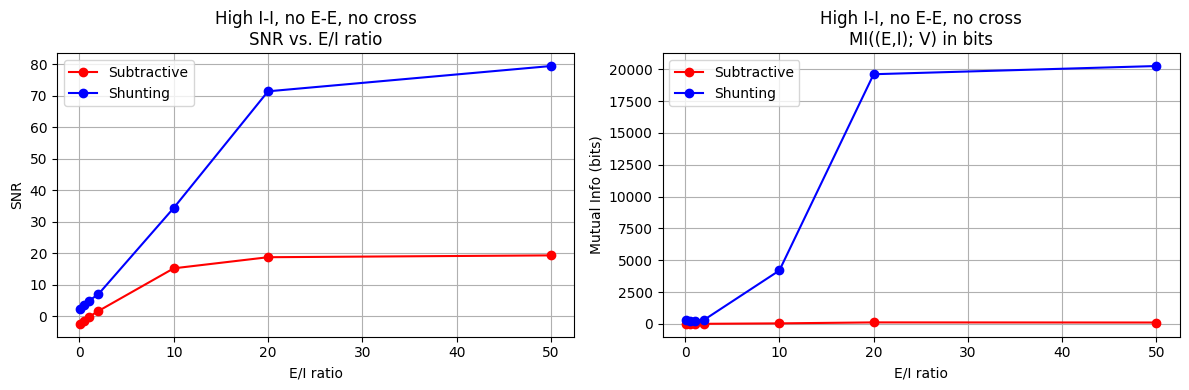

/tmp/ipykernel_2814478/845235532.py:76: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  X = np.random.multivariate_normal(mean, cov, size=num_samples)


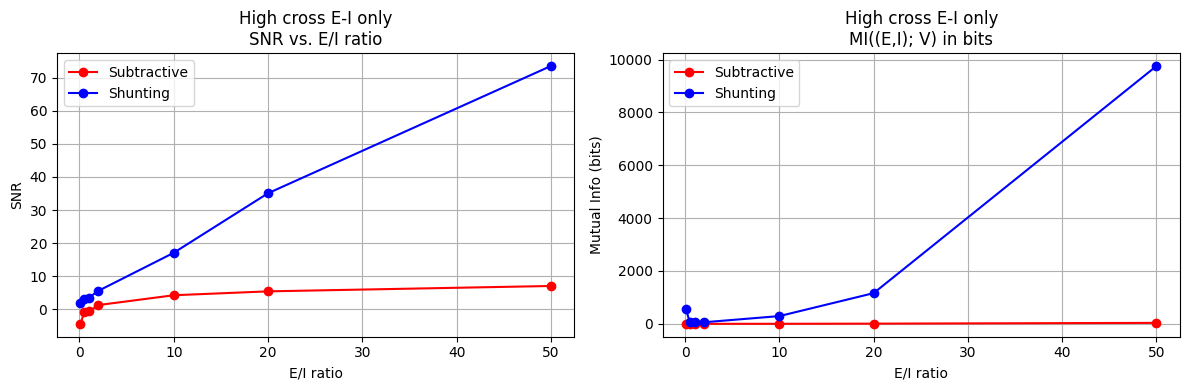

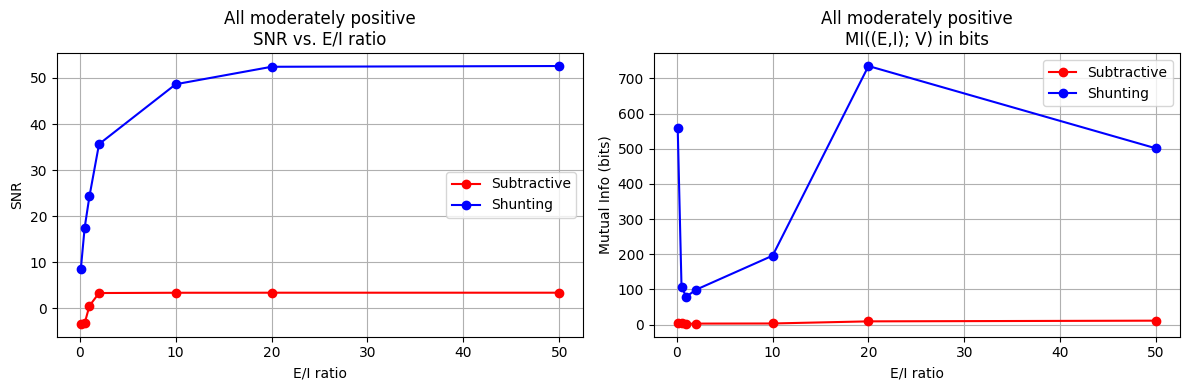

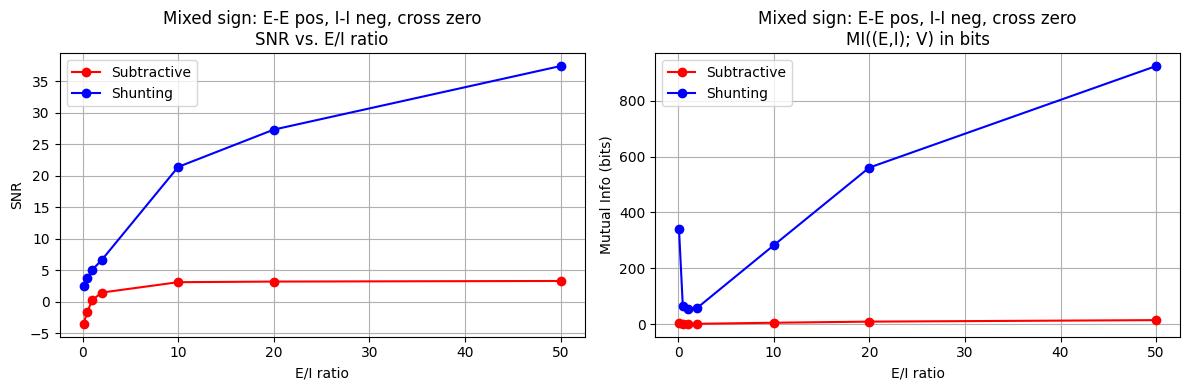

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit  # sigmoid for [0,1] data

# =====================================================================
# CONFIGURATION
# =====================================================================
NUM_SAMPLES    = 100_000   # number of random samples per condition
TOTAL_SYNAPSES = 100        # fixed total E + I
RATIOS         = [0.1, 0.5, 1.0, 2.0, 10.0, 20.0, 50.0]  # E/I ratio => E = round(ratio/(ratio+1)*TOTAL), I = remainder

# Define several correlation structures (schemes) to test:
# (name, rho_EE, rho_II, rho_EI)
#   - rho_EE: correlation among excitatory synapses
#   - rho_II: correlation among inhibitory synapses
#   - rho_EI: correlation between excitatory and inhibitory
CORR_SCHEMES = [
    ("High E-E, no I-I, no cross", 0.8, 0.0, 0.0),
    ("High I-I, no E-E, no cross", 0.0, 0.8, 0.0),
    ("High cross E-I only",       0.0, 0.0, 0.8),
    ("All moderately positive",    0.5, 0.5, 0.5),
    ("Mixed sign: E-E pos, I-I neg, cross zero", 0.5, -0.5, 0.0),
]

# Binning for MI:
BINS_2D = 20
BINS_V  = 20

# =====================================================================
# HELPER FUNCTIONS
# =====================================================================

def build_block_cov(e_count, i_count, rho_EE, rho_II, rho_EI):
    """
    Build a block-structured covariance matrix of dimension (e_count + i_count).
    - Among excitatory (E-E) = rho_EE
    - Among inhibitory (I-I) = rho_II
    - Between excitatory and inhibitory (E-I) = rho_EI
    On the diagonal = 1.0.
    Off-diagonal within E block => rho_EE, within I block => rho_II, cross-block => rho_EI.
    """
    dim = e_count + i_count
    cov = np.zeros((dim, dim), dtype=np.float64)
    
    # Fill E-E block
    for i in range(e_count):
        for j in range(e_count):
            cov[i, j] = rho_EE if i != j else 1.0

    # Fill I-I block
    for i in range(i_count):
        for j in range(i_count):
            row = e_count + i
            col = e_count + j
            cov[row, col] = rho_II if i != j else 1.0

    # Fill cross E-I block (symmetric)
    for i in range(e_count):
        for j in range(i_count):
            row = i
            col = e_count + j
            cov[row, col] = rho_EI
            cov[col, row] = rho_EI
    
    return cov

def generate_block_sigmoid(e_count, i_count, rho_EE, rho_II, rho_EI, num_samples):
    """
    1) Build block-structured covariance with (e_count + i_count) dims.
    2) Sample from the resulting MVN(0, Cov).
    3) Pass through sigmoid => each dimension in [0,1].
    Returns array (num_samples, e_count + i_count).
    """
    cov = build_block_cov(e_count, i_count, rho_EE, rho_II, rho_EI)
    mean = np.zeros(e_count + i_count, dtype=np.float64)
    X = np.random.multivariate_normal(mean, cov, size=num_samples)
    return expit(X)  # shape (N, dim) in [0,1]

def compute_SNR(values):
    """
    SNR = mean(values) / std(values) for 1D array.
    """
    m = np.mean(values)
    s = np.std(values)
    return m / (s + 1e-12)

def estimate_mutual_information(E_vals, I_vals, V_vals, bins_2d=20, bins_v=20):
    """
    Estimate MI( (E,I); V ) by binning in 2D for (E,I) and 1D for V.
    Returns MI in nats. For bits => MI_bits = MI_nats / log(2).
    """
    # Determine ranges
    e_min, e_max = E_vals.min(), E_vals.max()
    i_min, i_max = I_vals.min(), I_vals.max()
    v_min, v_max = V_vals.min(), V_vals.max()

    # 2D histogram p(E,I)
    hist_EI, edgesE, edgesI = np.histogram2d(
        E_vals, I_vals,
        bins=bins_2d,
        range=[[e_min, e_max], [i_min, i_max]],
        density=True
    )
    # 1D histogram p(V)
    hist_V, edgesV = np.histogram(
        V_vals, bins=bins_v,
        range=(v_min, v_max),
        density=True
    )
    # 3D histogram p(E,I,V)
    data_3d = np.column_stack((E_vals, I_vals, V_vals))
    hist_3d, edges3d = np.histogramdd(
        data_3d,
        bins=(bins_2d, bins_2d, bins_v),
        range=[[e_min,e_max], [i_min,i_max], [v_min,v_max]],
        density=True
    )

    MI = 0.0
    for i_e in range(bins_2d):
        for i_i in range(bins_2d):
            for i_v in range(bins_v):
                p_eiv = hist_3d[i_e, i_i, i_v]
                if p_eiv > 0:
                    p_ei = hist_EI[i_e, i_i]
                    p_v  = hist_V[i_v]
                    MI += p_eiv * np.log((p_eiv + 1e-20)/((p_ei*p_v)+1e-20))
    return MI  # nats

# =====================================================================
# MAIN: For each correlation scheme, we loop over RATIOS, do one figure.
# =====================================================================

for (scheme_name, rho_EE, rho_II, rho_EI) in CORR_SCHEMES:

    # Arrays to store results for each ratio
    ratio_list      = []
    snr_sub_list    = []
    snr_shunt_list  = []
    mi_sub_list     = []
    mi_shunt_list   = []

    for ratio in RATIOS:
        # 1) define e_count, i_count with E + I = TOTAL_SYNAPSES
        e_count = int(round(ratio/(ratio + 1) * TOTAL_SYNAPSES))
        i_count = TOTAL_SYNAPSES - e_count

        # 2) generate random [0,1] input data with block correlation
        data_all = generate_block_sigmoid(
            e_count, i_count,
            rho_EE, rho_II, rho_EI,
            NUM_SAMPLES
        )
        excit_data = data_all[:, :e_count]
        inhib_data = data_all[:, e_count:]

        # 3) random synaptic weights in [0,1]
        wE = np.random.rand(e_count)
        wI = np.random.rand(i_count)

        # 4) sum up excitatory and inhibitory
        E_vals = np.sum(excit_data * wE[None, :], axis=1)
        I_vals = np.sum(inhib_data * wI[None, :], axis=1)

        # 5) compute subtractive vs. shunting outputs
        V_sub    = E_vals - I_vals
        V_shunt  = E_vals / (1.0 + E_vals + I_vals)

        # 6) SNR
        snr_sub   = compute_SNR(V_sub)
        snr_shunt = compute_SNR(V_shunt)

        # 7) MI( (E,I); V )
        mi_sub_nats = estimate_mutual_information(E_vals, I_vals, V_sub,
                                                  bins_2d=BINS_2D, bins_v=BINS_V)
        mi_shunt_nats = estimate_mutual_information(E_vals, I_vals, V_shunt,
                                                    bins_2d=BINS_2D, bins_v=BINS_V)

        # store results
        ratio_list.append(ratio)
        snr_sub_list.append(snr_sub)
        snr_shunt_list.append(snr_shunt)
        # convert nats -> bits for final plot
        mi_sub_list.append(mi_sub_nats / np.log(2))
        mi_shunt_list.append(mi_shunt_nats / np.log(2))

    # ---------------------------------------------------------
    # PLOT: We'll do a 1-figure with 2 subplots:
    # Left: SNR vs. ratio
    # Right: MI vs. ratio
    # We'll plot sub vs. shunt on same plot for easy comparison.
    # ---------------------------------------------------------
    fig, (ax_snr, ax_mi) = plt.subplots(1, 2, figsize=(12,4))

    ax_snr.plot(ratio_list, snr_sub_list, 'ro-', label='Subtractive')
    ax_snr.plot(ratio_list, snr_shunt_list, 'bo-', label='Shunting')
    ax_snr.set_title(f"{scheme_name}\nSNR vs. E/I ratio")
    ax_snr.set_xlabel("E/I ratio")
    ax_snr.set_ylabel("SNR")
    ax_snr.legend()
    ax_snr.grid(True)

    ax_mi.plot(ratio_list, mi_sub_list, 'ro-', label='Subtractive')
    ax_mi.plot(ratio_list, mi_shunt_list, 'bo-', label='Shunting')
    ax_mi.set_title(f"{scheme_name}\nMI((E,I); V) in bits")
    ax_mi.set_xlabel("E/I ratio")
    ax_mi.set_ylabel("Mutual Info (bits)")
    ax_mi.legend()
    ax_mi.grid(True)

    plt.tight_layout()
    plt.show()

BLOCK 1: Variation of E/I numbers => SNR, MI


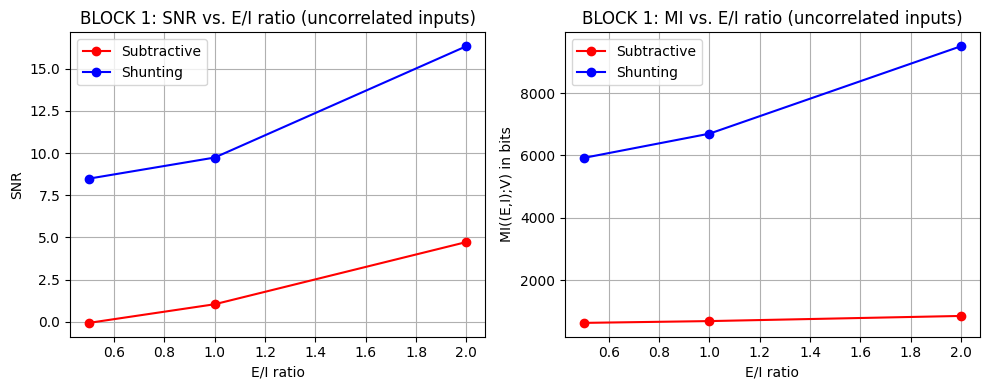

BLOCK 2: Shunting vs. non-shunting for correlation sweep


/tmp/ipykernel_2814478/3956375127.py:97: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  X = np.random.multivariate_normal(mean, cov, size=num_samples)


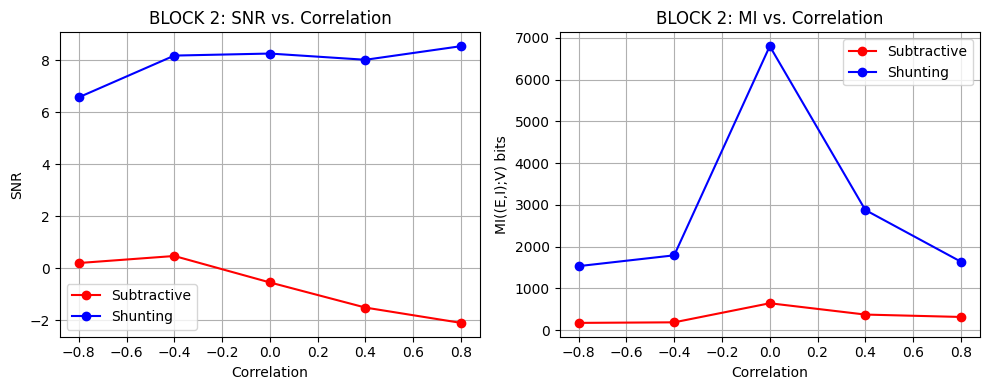

BLOCK 3: Noise resilience with E/I correlation, vary #E,#I


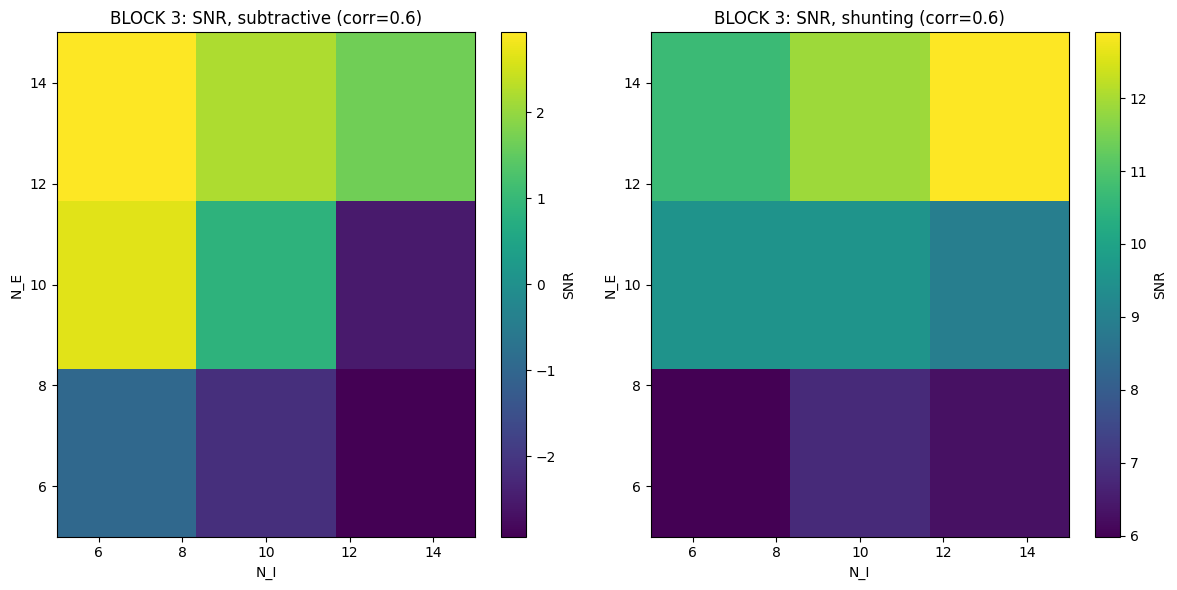

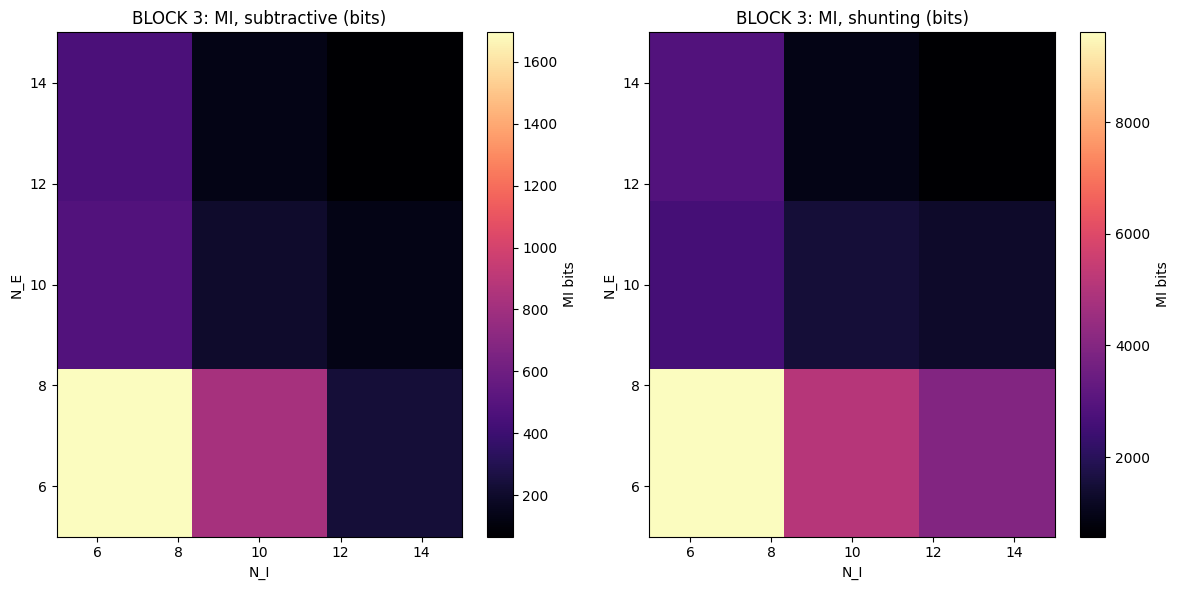

BLOCK 4: Signal vs. noise distribution among E/I
BLOCK 4: scenario with E carrying signal + noise, I purely noise => I(s; Vsub) = -177.182 bits,  I(s; Vsh) = -3923.931 bits


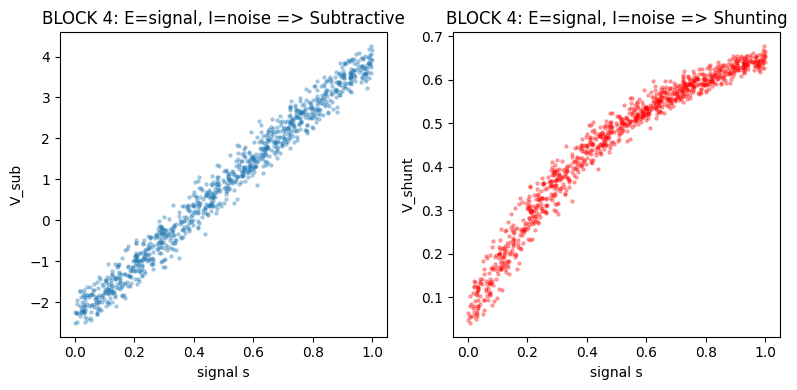

Done with the 4-block analyses!


In [3]:
"""
dendritic_analysis_notebook.ipynb

This notebook is structured into four major blocks:

  BLOCK 1: Effect of number of E/I synapses on SNR, MI.
  BLOCK 2: Effect of Shunting vs. Subtractive
  BLOCK 3: Noise resilience with correlation
  BLOCK 4: Distributing signal vs. noise among E, I

We provide some basic analytical references in each block's comments,
then do a numerical simulation + plot.
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit
import itertools

# Some helper functions

def compute_subtractive(E, I):
    return E - I

def compute_shunting(E, I):
    return E / (1.0 + E + I + 1e-12)  # small epsilon to avoid /0

def compute_snr(vals):
    m = np.mean(vals)
    s = np.std(vals)
    return m / (s + 1e-12)

def estimate_MI(E_vals, I_vals, V_vals, bins_2d=20, bins_v=20):
    """
    Estimate MI( (E,I); V ) using a naive histogram approach.
    Returns MI in nats.
    """
    e_min, e_max = E_vals.min(), E_vals.max()
    i_min, i_max = I_vals.min(), I_vals.max()
    v_min, v_max = V_vals.min(), V_vals.max()

    hist_EI, edgesEI_e, edgesEI_i = np.histogram2d(
        E_vals, I_vals, bins=bins_2d, 
        range=[[e_min,e_max],[i_min,i_max]], density=True)
    hist_V, edgesV = np.histogram(V_vals, bins=bins_v,
                                  range=(v_min,v_max), density=True)

    data_3d = np.column_stack((E_vals, I_vals, V_vals))
    hist_3d, edges_3d = np.histogramdd(
        data_3d, bins=(bins_2d, bins_2d, bins_v),
        range=[[e_min,e_max],[i_min,i_max],[v_min,v_max]],
        density=True)

    MI_nats = 0.0
    for ix_e in range(bins_2d):
        for ix_i in range(bins_2d):
            for ix_v in range(bins_v):
                p_eiv = hist_3d[ix_e, ix_i, ix_v]
                if p_eiv > 0:
                    p_ei = hist_EI[ix_e, ix_i]
                    p_v  = hist_V[ix_v]
                    MI_nats += p_eiv * np.log((p_eiv + 1e-20) / ((p_ei * p_v)+1e-20))
    return MI_nats

def generate_random_inputs_ei(N_E, N_I, num_samples, 
                              meanE=0.5, meanI=0.5,
                              sigmaE=0.2, sigmaI=0.2,
                              correlation=0.0,
                              mode="independent"):
    """
    Return arrays E_vals, I_vals each shape (num_samples,).
    If mode="independent", we just do e.g. E ~ logistic or something.
    If mode="gauss_sigmoid", we do correlated draws then pass through sigmoid.
    """
    # For simplicity, let's do correlated draws from bivariate normal (2D),
    # then pass through a sum for N_E or N_I synapses.
    # Or you can combine a bigger covariance if you want more sophisticated correlation within E, within I, cross E-I, etc.

    if mode == "independent":
        # Generate E as N_E uniform(0,1) * random weights, but let's do a sum
        e_data = np.random.rand(num_samples, N_E)  # in [0,1]
        i_data = np.random.rand(num_samples, N_I)
        # Weighted sums?
        wE = np.random.rand(N_E)
        wI = np.random.rand(N_I)
        E_vals = np.sum(e_data*wE, axis=1)
        I_vals = np.sum(i_data*wI, axis=1)
        return E_vals, I_vals
    
    elif mode == "gauss_sigmoid":
        # We do a big dimension = N_E + N_I, build correlation = correlation for everything, for simplicity
        # Then pass through wE, wI
        dim = N_E + N_I
        cov = np.full((dim, dim), correlation)
        np.fill_diagonal(cov, 1.0)
        mean = np.zeros(dim)
        X = np.random.multivariate_normal(mean, cov, size=num_samples)
        # pass through expit => in [0,1]
        X_01 = expit(X)
        # separate
        X_E = X_01[:, :N_E]
        X_I = X_01[:, N_E:]
        wE = np.random.rand(N_E)
        wI = np.random.rand(N_I)
        E_vals = np.sum(X_E * wE[None,:], axis=1)
        I_vals = np.sum(X_I * wI[None,:], axis=1)
        return E_vals, I_vals


##############################################################################
# BLOCK 1: Variation of E/I numbers => SNR, MI
##############################################################################
print("BLOCK 1: Variation of E/I numbers => SNR, MI")

# For demonstration, let's fix total synapses = 20, vary ratio in [0.5, 1, 2]
# We'll do sub vs. shunt. We'll do a single correlation=0 case for clarity.

TOTAL_SYN = 20
ratios = [0.5, 1.0, 2.0]
num_samples = 100_000
corr_val = 0.0  # no correlation for now

snr_sub_all = []
snr_shunt_all = []
mi_sub_all = []
mi_shunt_all = []

for r in ratios:
    N_E = int(round(TOTAL_SYN*r/(r+1)))
    N_I = TOTAL_SYN - N_E

    E_vals, I_vals = generate_random_inputs_ei(N_E, N_I,
                                               num_samples,
                                               correlation=corr_val,
                                               mode="gauss_sigmoid")
    V_sub = compute_subtractive(E_vals, I_vals)
    V_shunt = compute_shunting(E_vals, I_vals)
    snr_sub = compute_snr(V_sub)
    snr_sh = compute_snr(V_shunt)
    mi_sub_nats = estimate_MI(E_vals, I_vals, V_sub)
    mi_sh_nats  = estimate_MI(E_vals, I_vals, V_shunt)
    
    snr_sub_all.append(snr_sub)
    snr_shunt_all.append(snr_sh)
    mi_sub_all.append(mi_sub_nats/np.log(2))   # in bits
    mi_shunt_all.append(mi_sh_nats/np.log(2)) # in bits

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(ratios, snr_sub_all, 'ro-', label='Subtractive')
plt.plot(ratios, snr_shunt_all, 'bo-', label='Shunting')
plt.xlabel('E/I ratio')
plt.ylabel('SNR')
plt.title('BLOCK 1: SNR vs. E/I ratio (uncorrelated inputs)')
plt.grid(True)
plt.legend()

plt.subplot(1,2,2)
plt.plot(ratios, mi_sub_all, 'ro-', label='Subtractive')
plt.plot(ratios, mi_shunt_all, 'bo-', label='Shunting')
plt.xlabel('E/I ratio')
plt.ylabel('MI((E,I);V) in bits')
plt.title('BLOCK 1: MI vs. E/I ratio (uncorrelated inputs)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


##############################################################################
# BLOCK 2: Effect of shunting vs. non-shunting for fixed E/I but vary correlation
##############################################################################
print("BLOCK 2: Shunting vs. non-shunting for correlation sweep")

N_E = 10
N_I = 10
corr_sweep = np.linspace(-0.8, 0.8, 5)
snr_sub_list = []
snr_shunt_list = []
mi_sub_list = []
mi_shunt_list = []

for cval in corr_sweep:
    E_vals, I_vals = generate_random_inputs_ei(N_E, N_I,
                                               num_samples,
                                               correlation=cval,
                                               mode="gauss_sigmoid")
    V_sub = compute_subtractive(E_vals, I_vals)
    V_shunt = compute_shunting(E_vals, I_vals)
    snr_sub = compute_snr(V_sub)
    snr_sh  = compute_snr(V_shunt)
    mi_sub_nats = estimate_MI(E_vals, I_vals, V_sub)
    mi_sh_nats  = estimate_MI(E_vals, I_vals, V_shunt)
    
    snr_sub_list.append(snr_sub)
    snr_shunt_list.append(snr_sh)
    mi_sub_list.append(mi_sub_nats/np.log(2))
    mi_shunt_list.append(mi_sh_nats/np.log(2))

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(corr_sweep, snr_sub_list, 'ro-', label='Subtractive')
plt.plot(corr_sweep, snr_shunt_list, 'bo-', label='Shunting')
plt.xlabel('Correlation')
plt.ylabel('SNR')
plt.title('BLOCK 2: SNR vs. Correlation')
plt.grid(True)
plt.legend()

plt.subplot(1,2,2)
plt.plot(corr_sweep, mi_sub_list, 'ro-', label='Subtractive')
plt.plot(corr_sweep, mi_shunt_list, 'bo-', label='Shunting')
plt.xlabel('Correlation')
plt.ylabel('MI((E,I);V) bits')
plt.title('BLOCK 2: MI vs. Correlation')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


##############################################################################
# BLOCK 3: Noise resilience with E/I correlation
##############################################################################
print("BLOCK 3: Noise resilience with E/I correlation, vary #E,#I")

# We'll define a function that for each (N_E,N_I) and correlation c,
# measures SNR/MI. Then plot them as a grid, for instance.

E_vals_list = [5, 10, 15]
I_vals_list = [5, 10, 15]
corr_val = 0.6  # pick a fairly high correlation to test "noise resilience"

results_snr_sub = np.zeros((len(E_vals_list), len(I_vals_list)))
results_snr_shunt = np.zeros_like(results_snr_sub)
results_mi_sub = np.zeros_like(results_snr_sub)
results_mi_shunt = np.zeros_like(results_snr_sub)

for iE, NE in enumerate(E_vals_list):
    for iI, NI in enumerate(I_vals_list):
        Edata, Idata = generate_random_inputs_ei(NE, NI,
                                                 num_samples,
                                                 correlation=corr_val,
                                                 mode="gauss_sigmoid")
        Vsub = compute_subtractive(Edata, Idata)
        Vsh = compute_shunting(Edata, Idata)
        snrS = compute_snr(Vsub)
        snrH = compute_snr(Vsh)
        miS  = estimate_MI(Edata, Idata, Vsub)/np.log(2)
        miH  = estimate_MI(Edata, Idata, Vsh)/np.log(2)
        results_snr_sub[iE, iI]   = snrS
        results_snr_shunt[iE, iI] = snrH
        results_mi_sub[iE, iI]    = miS
        results_mi_shunt[iE, iI]  = miH

# We can make contour plots or heatmaps
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title(f"BLOCK 3: SNR, subtractive (corr={corr_val})")
plt.imshow(results_snr_sub, origin='lower', cmap='viridis',
           extent=[I_vals_list[0], I_vals_list[-1],
                   E_vals_list[0], E_vals_list[-1]],
           aspect='auto')
plt.colorbar(label='SNR')
plt.xlabel('N_I')
plt.ylabel('N_E')

plt.subplot(1,2,2)
plt.title(f"BLOCK 3: SNR, shunting (corr={corr_val})")
plt.imshow(results_snr_shunt, origin='lower', cmap='viridis',
           extent=[I_vals_list[0], I_vals_list[-1],
                   E_vals_list[0], E_vals_list[-1]],
           aspect='auto')
plt.colorbar(label='SNR')
plt.xlabel('N_I')
plt.ylabel('N_E')

plt.tight_layout()
plt.show()

# Similarly for MI:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title(f"BLOCK 3: MI, subtractive (bits)")
plt.imshow(results_mi_sub, origin='lower', cmap='magma',
           extent=[I_vals_list[0], I_vals_list[-1],
                   E_vals_list[0], E_vals_list[-1]],
           aspect='auto')
plt.colorbar(label='MI bits')
plt.xlabel('N_I')
plt.ylabel('N_E')

plt.subplot(1,2,2)
plt.title(f"BLOCK 3: MI, shunting (bits)")
plt.imshow(results_mi_shunt, origin='lower', cmap='magma',
           extent=[I_vals_list[0], I_vals_list[-1],
                   E_vals_list[0], E_vals_list[-1]],
           aspect='auto')
plt.colorbar(label='MI bits')
plt.xlabel('N_I')
plt.ylabel('N_E')

plt.tight_layout()
plt.show()


##############################################################################
# BLOCK 4: Distributing signal in E vs. noise in I
##############################################################################
print("BLOCK 4: Signal vs. noise distribution among E/I")

# We'll define a scenario where 'E' has some signal dimension s in [0,1], while 'I' is purely noise.

def generate_signal_plus_noise(num_samples, NE, NI,
                               correlation_e=0.0,
                               correlation_i=0.0,
                               correlation_ei=0.0):
    """
    Example: 
    - We'll interpret 'signal' as s ~ Uniform(0,1). Then each excit synapse x_{E_j} = s + noise_j, clipped [0,1].
    - Inhibitory synapses = noise only.
    - For correlation, we might do a more advanced block approach,
      but let's keep it simpler for demonstration.
    """
    # 1) sample the signal
    s_vals = np.random.rand(num_samples)  # uniform in [0,1]
    # 2) create excit data: x_{E_j} = s + noise, clipped
    # For correlation among excit synapses, we could do a 1D factor for s, plus correlated noise.
    # We'll do a simple approach: x_{E_j} = s + alpha * noise_j. 
    # For now let's keep it uncorrelated, ignoring correlation_e param for brevity or just partial usage.
    # In practice, you'd build a block covariance for (NE + NI) dims.
    
    # Let noise for excit = normal(0, 0.1), then x_{E_j} = s + that noise, clipped
    noise_e = 0.1 * np.random.randn(num_samples, NE)
    # xE = np.clip(s_vals[:,None] + noise_e, 0, 1)
    xE = s_vals[:,None] + noise_e
    xE = np.clip(xE, 0, 1)
    
    # Inhib => purely noise, for NI synapses
    noise_i = 0.1 * np.random.randn(num_samples, NI)
    # Shift them in [0,1]? e.g. 0.5 + that noise
    xI = 0.5 + noise_i
    xI = np.clip(xI, 0, 1)
    
    # Weighted sums
    wE = np.random.rand(NE)
    wI = np.random.rand(NI)
    Evals = np.sum(xE*wE, axis=1)
    Ivals = np.sum(xI*wI, axis=1)
    return s_vals, Evals, Ivals


# Let's do a small demonstration:
NE = 10
NI = 10
s_vals, Evals, Ivals = generate_signal_plus_noise( num_samples=50000,
                                                   NE=NE,
                                                   NI=NI )

Vsub = Evals - Ivals
Vsh  = Evals / (1 + Evals + Ivals + 1e-12)

# We can measure I(s; Vsub) and I(s; Vsh).
# We'll do a binning approach: p(s,V).
# We'll unify s and V in a 2D histogram. 
# We won't consider I(s; (E,I)) but you could as well.
def estimate_MI_sv(s_vals, v_vals, bins_s=20, bins_v=20):
    s_min, s_max = s_vals.min(), s_vals.max()
    v_min, v_max = v_vals.min(), v_vals.max()
    hist_sv, edges_s, edges_v = np.histogram2d(s_vals, v_vals,
                                               bins=(bins_s, bins_v),
                                               range=[[s_min, s_max],[v_min, v_max]],
                                               density=True)
    p_s = np.sum(hist_sv, axis=1)
    p_v = np.sum(hist_sv, axis=0)
    mi_nats = 0.0
    for is_ in range(bins_s):
        for iv_ in range(bins_v):
            p_sv = hist_sv[is_, iv_]
            if p_sv>0:
                ps = p_s[is_]
                pv = p_v[iv_]
                mi_nats += p_sv*np.log((p_sv+1e-20)/(ps*pv+1e-20))
    return mi_nats

mi_sub_sv  = estimate_MI_sv(s_vals, Vsub)/np.log(2)
mi_shunt_sv= estimate_MI_sv(s_vals, Vsh )/np.log(2)

print(f"BLOCK 4: scenario with E carrying signal + noise, I purely noise => I(s; Vsub) = {mi_sub_sv:.3f} bits,  I(s; Vsh) = {mi_shunt_sv:.3f} bits")

# Optionally, let's do a quick plot of s vs. V to see any shape:
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.scatter(s_vals[:1000], Vsub[:1000], s=5, alpha=0.3)
plt.xlabel('signal s')
plt.ylabel('V_sub')
plt.title('BLOCK 4: E=signal, I=noise => Subtractive')

plt.subplot(1,2,2)
plt.scatter(s_vals[:1000], Vsh[:1000], s=5, alpha=0.3, c='r')
plt.xlabel('signal s')
plt.ylabel('V_shunt')
plt.title('BLOCK 4: E=signal, I=noise => Shunting')
plt.tight_layout()
plt.show()

print("Done with the 4-block analyses!")

BLOCK 1: E vs. I ratio =>


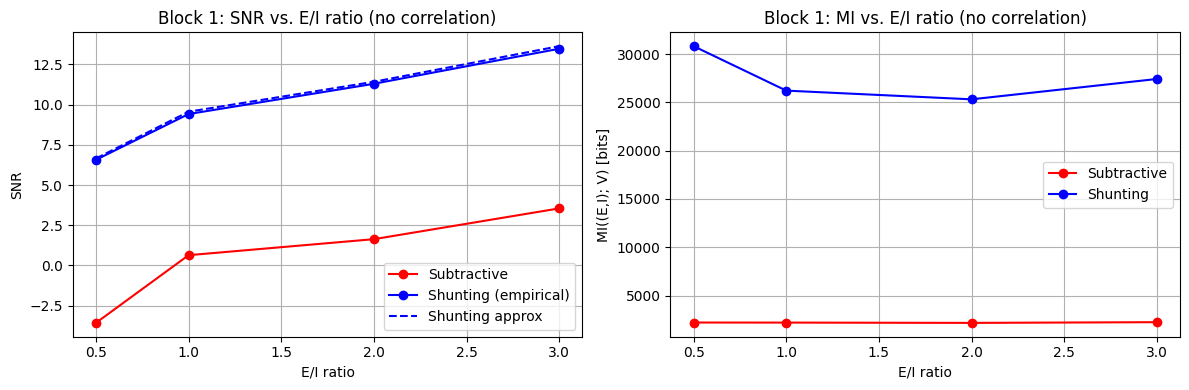


BLOCK 2: Shunting vs. Subtractive, correlation structures =>


/tmp/ipykernel_2814478/3029087993.py:126: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  X = np.random.multivariate_normal(mean, cov, size=num_samples)


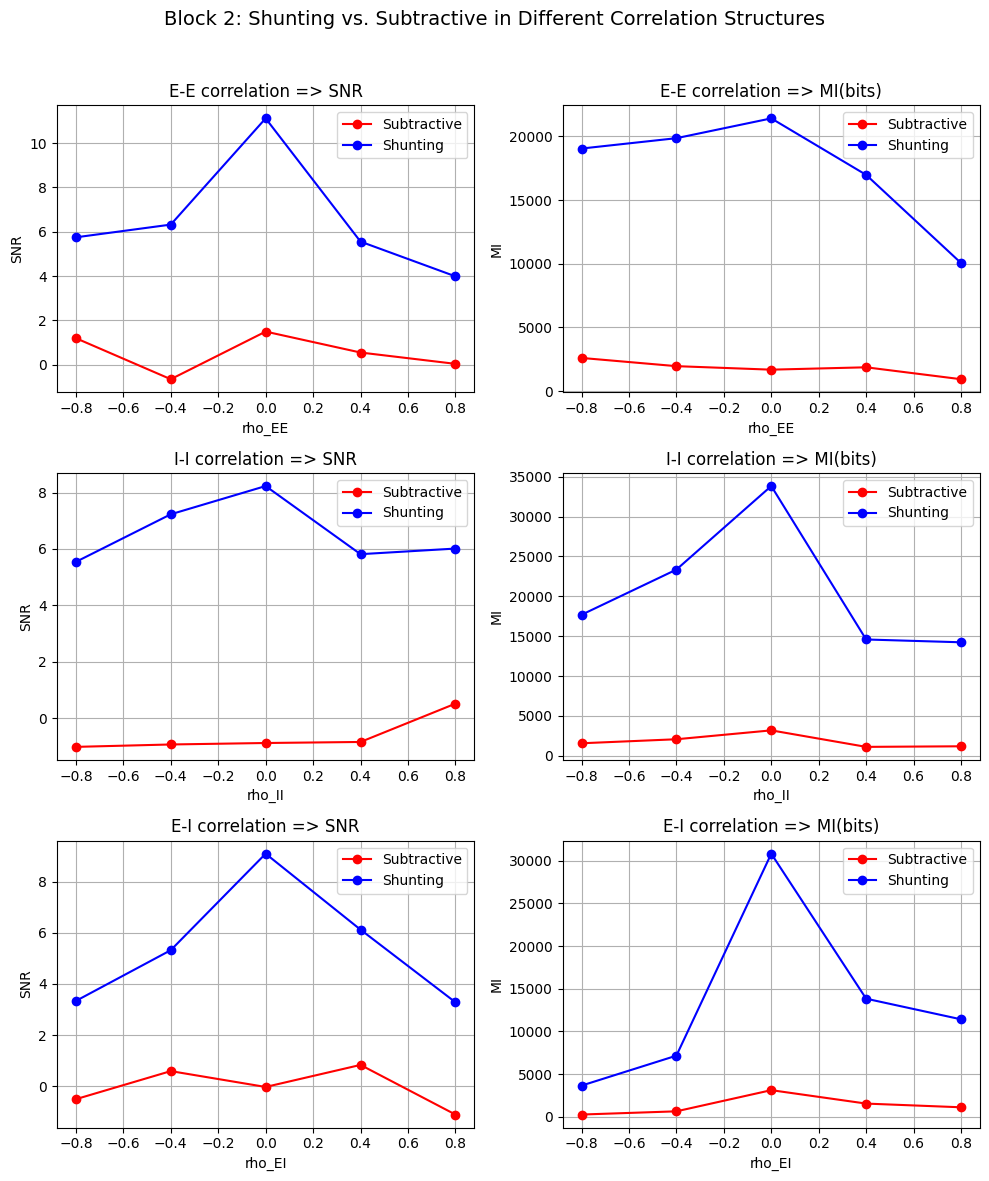


BLOCK 3: Noise Resilience with amplitude =>


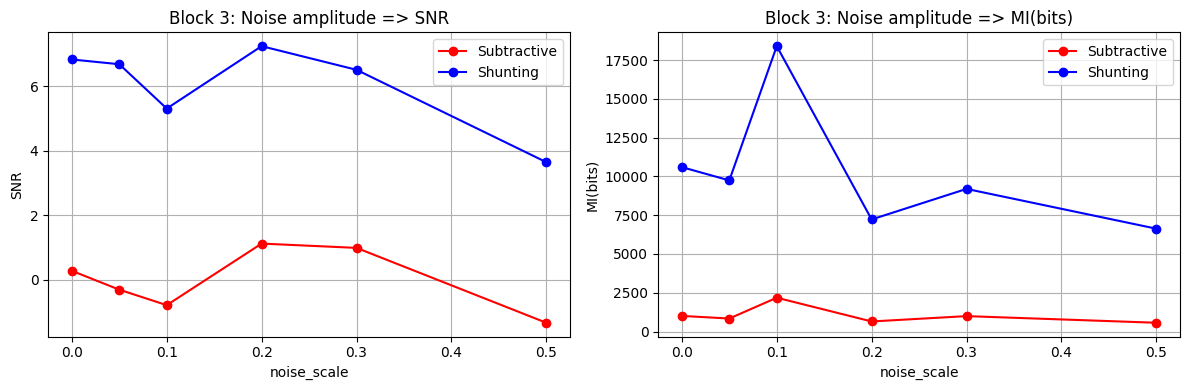


BLOCK 4: Distributing signal vs. noise =>


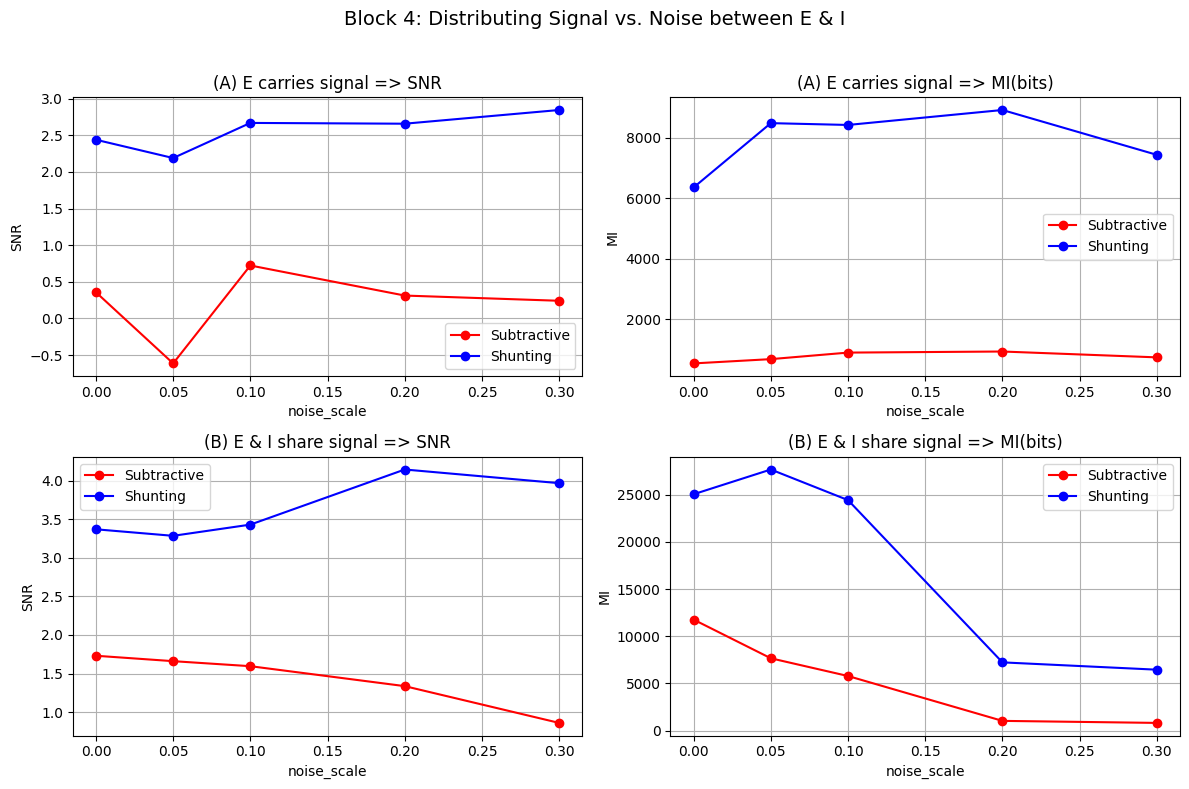

In [4]:
"""
single_branch_analyses.ipynb

Detailed analyses + simulations for a single dendritic branch, focusing on:
1) E vs. I synapse counts
2) Shunting vs. subtractive
3) Noise resilience with correlations
4) Distributing signal vs. noise between E and I
and we include partial correlation structures: E-E, I-I, E-I.

We'll do each scenario in a separate block. We'll also attempt some
analytical expansions vs. actual numeric measures for SNR & MI.
"""

import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.special import expit

# ================================================
#  A) HELPER FUNCTIONS
# ================================================

def dendritic_output_subtractive(E, I):
    """Subtractive output: V = E - I."""
    return E - I

def dendritic_output_shunting(E, I):
    """Shunting output: V = E / (1 + E + I)."""
    return E / (1.0 + E + I + 1e-12)

def compute_SNR(vals):
    """Compute SNR = mean(vals) / std(vals)."""
    m = np.mean(vals)
    s = np.std(vals)
    return m / (s + 1e-12)

def estimate_mutual_information(E_vals, I_vals, V_vals, bins_2d=30, bins_v=30):
    """
    Estimate MI((E,I), V) via a 2D+1D => 3D histogram approach.
    Returns MI in nats. (Convert to bits by dividing by log(2).)
    """
    e_min, e_max = E_vals.min(), E_vals.max()
    i_min, i_max = I_vals.min(), I_vals.max()
    v_min, v_max = V_vals.min(), V_vals.max()
    
    hist_EI, edgesE, edgesI = np.histogram2d(
        E_vals, I_vals,
        bins=bins_2d,
        range=[[e_min,e_max],[i_min,i_max]],
        density=True
    )
    hist_V, edgesV = np.histogram(
        V_vals,
        bins=bins_v,
        range=(v_min, v_max),
        density=True
    )
    data_3d = np.column_stack((E_vals, I_vals, V_vals))
    hist_3d, edges3d = np.histogramdd(
        data_3d,
        bins=(bins_2d,bins_2d,bins_v),
        range=[[e_min,e_max],[i_min,i_max],[v_min,v_max]],
        density=True
    )

    MI = 0.0
    for i_e in range(bins_2d):
        for i_i in range(bins_2d):
            for i_v in range(bins_v):
                p_eiv = hist_3d[i_e, i_i, i_v]
                if p_eiv>0:
                    p_ei = hist_EI[i_e, i_i]
                    p_v  = hist_V[i_v]
                    MI += p_eiv*math.log( (p_eiv +1e-20)/((p_ei*p_v)+1e-20) )
    return MI  # nats

def build_block_cov(e_count, i_count, rho_EE=0.0, rho_II=0.0, rho_EI=0.0):
    """
    Build a covariance matrix for e_count + i_count dimensions, with:
     - within-E correlation = rho_EE,
     - within-I correlation = rho_II,
     - cross E-I correlation = rho_EI.
    """
    dim = e_count + i_count
    cov = np.zeros((dim, dim), dtype=np.float64)
    
    # E block
    for i in range(e_count):
        for j in range(e_count):
            if i==j:
                cov[i,j] = 1.0
            else:
                cov[i,j] = rho_EE
    
    # I block
    for i in range(i_count):
        row = e_count + i
        for j in range(i_count):
            col = e_count + j
            if i==j:
                cov[row,col] = 1.0
            else:
                cov[row,col] = rho_II

    # cross E-I
    for i in range(e_count):
        for j in range(i_count):
            row = i
            col = e_count + j
            cov[row,col] = rho_EI
            cov[col,row] = rho_EI
    
    return cov

def generate_correlated_data(e_count, i_count, num_samples=50000,
                             rho_EE=0.0, rho_II=0.0, rho_EI=0.0):
    """
    Build a block covariance, sample from MVN(0, cov),
    pass each dimension through a sigmoid => [0,1].
    Return excit_data, inhib_data shaped (num_samples, e_count or i_count).
    """
    dim = e_count + i_count
    cov = build_block_cov(e_count, i_count, rho_EE, rho_II, rho_EI)
    mean = np.zeros(dim)
    X = np.random.multivariate_normal(mean, cov, size=num_samples)
    X_sigmoid = expit(X)
    excit_data = X_sigmoid[:,:e_count]
    inhib_data = X_sigmoid[:, e_count:]
    return excit_data, inhib_data

def approximate_shunting_snr(muE, muI, varE, varI, covEI):
    """
    Return an approximate SNR for V_shunt = E/(1+E+I), using the first-order expansions:
      alpha = (1 + muI)/(1+muE+muI)^2
      beta  = -muE/(1+muE+muI)^2
    var_shunt approx = alpha^2 varE + beta^2 varI + 2 alpha beta covEI
    mu_shunt = muE/(1+ muE+ muI)
    SNR = mu_shunt / sqrt(var_shunt).
    """
    denom = (1.0 + muE + muI)
    mu_sh = muE / denom
    alpha = (1.0 + muI)/(denom**2)
    beta  = - muE/(denom**2)
    var_sh = alpha**2 * varE + beta**2 * varI + 2.0*alpha*beta*covEI
    snr = mu_sh / (math.sqrt(var_sh + 1e-12))
    return snr

# ================================================
#  B) MAIN NOTEBOOK BLOCKS
# ================================================

# =============== BLOCK 1 ===============
# E vs. I ratio, no advanced correlation.
def block1_vary_EI_ratio():
    """
    Fix total synapses N=20, vary ratio E/I.
    We'll do both subtractive & shunting; measure empirical SNR & MI.
    We'll also do partial derivative expansions for shunting's SNR 
    to compare to the real data.
    No correlation in this block.
    """
    total_syn = 20
    ratios = [0.5, 1.0, 2.0, 3.0]
    num_samples = 50000

    snr_sub_list = []
    snr_shunt_list = []
    snr_shunt_approx_list = []
    mi_sub_list = []
    mi_shunt_list = []

    for ratio in ratios:
        E_count = int(round(ratio/(1+ratio)*total_syn))
        I_count = total_syn - E_count
        
        # generate correlated data with no correlation
        excit_data, inhib_data = generate_correlated_data(E_count, I_count, num_samples,
                                                          rho_EE=0.0, rho_II=0.0, rho_EI=0.0)
        wE = np.random.rand(E_count)
        wI = np.random.rand(I_count)

        E_vals = np.sum(excit_data*wE[None,:], axis=1)
        I_vals = np.sum(inhib_data*wI[None,:], axis=1)

        V_sub = dendritic_output_subtractive(E_vals, I_vals)
        V_sh  = dendritic_output_shunting(E_vals, I_vals)

        # measure SNR
        snr_sub = compute_SNR(V_sub)
        snr_sh  = compute_SNR(V_sh)

        # approximate SNR for shunting
        muE = np.mean(E_vals); muI = np.mean(I_vals)
        varE= np.var(E_vals);  varI= np.var(I_vals)
        covEI= np.cov(E_vals, I_vals)[0,1]
        snr_sh_approx = approximate_shunting_snr(muE, muI, varE, varI, covEI)

        # measure MI
        mi_sub_nats   = estimate_mutual_information(E_vals, I_vals, V_sub)
        mi_shunt_nats = estimate_mutual_information(E_vals, I_vals, V_sh)
        mi_sub_bits   = mi_sub_nats/np.log(2)
        mi_shunt_bits = mi_shunt_nats/np.log(2)

        snr_sub_list.append(snr_sub)
        snr_shunt_list.append(snr_sh)
        snr_shunt_approx_list.append(snr_sh_approx)
        mi_sub_list.append(mi_sub_bits)
        mi_shunt_list.append(mi_shunt_bits)

    # Plot
    fig, axs = plt.subplots(1,2, figsize=(12,4))
    ax_snr, ax_mi = axs

    ax_snr.plot(ratios, snr_sub_list, 'ro-', label='Subtractive')
    ax_snr.plot(ratios, snr_shunt_list, 'bo-', label='Shunting (empirical)')
    ax_snr.plot(ratios, snr_shunt_approx_list, 'b--', label='Shunting approx')
    ax_snr.set_xlabel("E/I ratio")
    ax_snr.set_ylabel("SNR")
    ax_snr.set_title("Block 1: SNR vs. E/I ratio (no correlation)")
    ax_snr.grid(True)
    ax_snr.legend()

    ax_mi.plot(ratios, mi_sub_list, 'ro-', label='Subtractive')
    ax_mi.plot(ratios, mi_shunt_list, 'bo-', label='Shunting')
    ax_mi.set_xlabel("E/I ratio")
    ax_mi.set_ylabel("MI((E,I); V) [bits]")
    ax_mi.set_title("Block 1: MI vs. E/I ratio (no correlation)")
    ax_mi.grid(True)
    ax_mi.legend()

    plt.tight_layout()
    plt.show()


# =============== BLOCK 2 ===============
# Shunting vs. no shunting, various correlation structures, see difference in SNR/MI
def block2_shunting_vs_subtractive_corr_structs():
    """
    We'll fix E_count=10, I_count=10, vary correlation in each of the three ways:
     - E-E correlation only,
     - I-I correlation only,
     - E-I correlation only.
    We'll do a small sweep of correlation from -0.8 to +0.8.
    Compare subtractive vs. shunting SNR & MI.
    """
    e_count = 10
    i_count = 10
    rhos = np.linspace(-0.8, 0.8, 5)
    
    # We'll define a small utility to measure snr/mi for a given correlation config
    def measure_snr_mi(rho_EE, rho_II, rho_EI):
        excit_data, inhib_data = generate_correlated_data(e_count, i_count, 50000,
                                                          rho_EE, rho_II, rho_EI)
        wE = np.random.rand(e_count)
        wI = np.random.rand(i_count)
        E_vals = np.sum(excit_data*wE[None,:], axis=1)
        I_vals = np.sum(inhib_data*wI[None,:], axis=1)
        V_sub = E_vals - I_vals
        V_sh  = E_vals/(1.0+E_vals+I_vals+1e-12)
        return (compute_SNR(V_sub),
                compute_SNR(V_sh),
                estimate_mutual_information(E_vals, I_vals, V_sub)/np.log(2),
                estimate_mutual_information(E_vals, I_vals, V_sh)/np.log(2))

    # We'll do 3 sub-blocks: E-E only, I-I only, E-I only
    # 2.1) E-E correlation
    snr_sub_EE = []
    snr_sh_EE = []
    mi_sub_EE = []
    mi_sh_EE = []
    for rho in rhos:
        s_sub, s_sh, m_sub, m_sh = measure_snr_mi(rho, 0.0, 0.0)
        snr_sub_EE.append(s_sub);  snr_sh_EE.append(s_sh)
        mi_sub_EE.append(m_sub);   mi_sh_EE.append(m_sh)

    # 2.2) I-I correlation
    snr_sub_II = []
    snr_sh_II = []
    mi_sub_II = []
    mi_sh_II = []
    for rho in rhos:
        s_sub, s_sh, m_sub, m_sh = measure_snr_mi(0.0, rho, 0.0)
        snr_sub_II.append(s_sub); snr_sh_II.append(s_sh)
        mi_sub_II.append(m_sub);  mi_sh_II.append(m_sh)

    # 2.3) E-I correlation
    snr_sub_EI = []
    snr_sh_EI = []
    mi_sub_EI = []
    mi_sh_EI = []
    for rho in rhos:
        s_sub, s_sh, m_sub, m_sh = measure_snr_mi(0.0, 0.0, rho)
        snr_sub_EI.append(s_sub); snr_sh_EI.append(s_sh)
        mi_sub_EI.append(m_sub);  mi_sh_EI.append(m_sh)

    # Plot 
    fig, axs = plt.subplots(3,2, figsize=(10,12))
    fig.suptitle("Block 2: Shunting vs. Subtractive in Different Correlation Structures", fontsize=14)
    # E-E
    ax_snr_EE, ax_mi_EE = axs[0]
    ax_snr_EE.plot(rhos, snr_sub_EE, 'ro-', label='Subtractive')
    ax_snr_EE.plot(rhos, snr_sh_EE, 'bo-', label='Shunting')
    ax_snr_EE.set_title("E-E correlation => SNR")
    ax_snr_EE.set_xlabel("rho_EE")
    ax_snr_EE.set_ylabel("SNR")
    ax_snr_EE.legend()
    ax_snr_EE.grid(True)

    ax_mi_EE.plot(rhos, mi_sub_EE, 'ro-', label='Subtractive')
    ax_mi_EE.plot(rhos, mi_sh_EE, 'bo-', label='Shunting')
    ax_mi_EE.set_title("E-E correlation => MI(bits)")
    ax_mi_EE.set_xlabel("rho_EE")
    ax_mi_EE.set_ylabel("MI")
    ax_mi_EE.legend()
    ax_mi_EE.grid(True)

    # I-I
    ax_snr_II, ax_mi_II = axs[1]
    ax_snr_II.plot(rhos, snr_sub_II, 'ro-', label='Subtractive')
    ax_snr_II.plot(rhos, snr_sh_II, 'bo-', label='Shunting')
    ax_snr_II.set_title("I-I correlation => SNR")
    ax_snr_II.set_xlabel("rho_II")
    ax_snr_II.set_ylabel("SNR")
    ax_snr_II.legend()
    ax_snr_II.grid(True)

    ax_mi_II.plot(rhos, mi_sub_II, 'ro-', label='Subtractive')
    ax_mi_II.plot(rhos, mi_sh_II, 'bo-', label='Shunting')
    ax_mi_II.set_title("I-I correlation => MI(bits)")
    ax_mi_II.set_xlabel("rho_II")
    ax_mi_II.set_ylabel("MI")
    ax_mi_II.legend()
    ax_mi_II.grid(True)

    # E-I
    ax_snr_EI, ax_mi_EI = axs[2]
    ax_snr_EI.plot(rhos, snr_sub_EI, 'ro-', label='Subtractive')
    ax_snr_EI.plot(rhos, snr_sh_EI, 'bo-', label='Shunting')
    ax_snr_EI.set_title("E-I correlation => SNR")
    ax_snr_EI.set_xlabel("rho_EI")
    ax_snr_EI.set_ylabel("SNR")
    ax_snr_EI.legend()
    ax_snr_EI.grid(True)

    ax_mi_EI.plot(rhos, mi_sub_EI, 'ro-', label='Subtractive')
    ax_mi_EI.plot(rhos, mi_sh_EI, 'bo-', label='Shunting')
    ax_mi_EI.set_title("E-I correlation => MI(bits)")
    ax_mi_EI.set_xlabel("rho_EI")
    ax_mi_EI.set_ylabel("MI")
    ax_mi_EI.legend()
    ax_mi_EI.grid(True)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


# =============== BLOCK 3 ===============
# Noise resilience: see how adding noise amplitude or correlation affects SNR & MI
# (some overlap with block2, but we'll do amplitude-based approach)
def block3_noise_resilience_with_amplitude():
    """
    We'll define a scenario where E_count=10, I_count=10, 
    we add random noise with a parameter noise_scale. 
    Then measure how SNR & MI degrade for subtractive vs shunting.
    This is a simpler 'uniform + noise' approach, no block correlation here.
    """
    e_count = 10
    i_count = 10
    noise_levels = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]
    snr_sub_list = []
    snr_shunt_list = []
    mi_sub_list = []
    mi_shunt_list = []

    def gen_data_uniform_noise(num_samples, e_count, i_count, nlev):
        # We'll do uniform base in [0,1], then add normal(0, nlev) => clip
        baseE = np.random.rand(num_samples, e_count)
        baseI = np.random.rand(num_samples, i_count)
        noiseE = np.random.randn(num_samples, e_count)*nlev
        noiseI = np.random.randn(num_samples, i_count)*nlev
        E_data = np.clip(baseE + noiseE, 0, 1)
        I_data = np.clip(baseI + noiseI, 0, 1)
        return E_data, I_data

    for nlev in noise_levels:
        E_data, I_data = gen_data_uniform_noise(50000, e_count, i_count, nlev)
        wE = np.random.rand(e_count)
        wI = np.random.rand(i_count)
        E_vals = np.sum(E_data*wE[None,:], axis=1)
        I_vals = np.sum(I_data*wI[None,:], axis=1)

        V_sub = E_vals - I_vals
        V_sh  = E_vals/(1.0+E_vals+I_vals+1e-12)
        snr_sub_list.append( compute_SNR(V_sub) )
        snr_shunt_list.append( compute_SNR(V_sh) )
        mi_sub_nats   = estimate_mutual_information(E_vals, I_vals, V_sub)
        mi_shunt_nats = estimate_mutual_information(E_vals, I_vals, V_sh)
        mi_sub_list.append(mi_sub_nats/np.log(2))
        mi_shunt_list.append(mi_shunt_nats/np.log(2))

    fig, (ax_snr, ax_mi) = plt.subplots(1,2, figsize=(12,4))
    ax_snr.plot(noise_levels, snr_sub_list, 'ro-', label='Subtractive')
    ax_snr.plot(noise_levels, snr_shunt_list, 'bo-', label='Shunting')
    ax_snr.set_title("Block 3: Noise amplitude => SNR")
    ax_snr.set_xlabel("noise_scale")
    ax_snr.set_ylabel("SNR")
    ax_snr.grid(True)
    ax_snr.legend()

    ax_mi.plot(noise_levels, mi_sub_list, 'ro-', label='Subtractive')
    ax_mi.plot(noise_levels, mi_shunt_list, 'bo-', label='Shunting')
    ax_mi.set_title("Block 3: Noise amplitude => MI(bits)")
    ax_mi.set_xlabel("noise_scale")
    ax_mi.set_ylabel("MI(bits)")
    ax_mi.grid(True)
    ax_mi.legend()

    plt.tight_layout()
    plt.show()

# =============== BLOCK 4 ===============
# Distributing signal vs noise in E or I
def block4_signal_noise_distribution():
    """
    We'll define 2 patterns:
      (A) E has the main signal, I is mostly noise.
      (B) Both E and I share partial signal, plus noise.

    We'll measure SNR & MI for each approach, under a range of noise scales.
    """
    def generate_data_signal_in_E(num_samples, e_count, i_count, noise_scale):
        # E gets a base signal s in [0,1], + noise
        s = np.random.rand(num_samples,1)  # main signal
        E_signal = np.clip(s + noise_scale*np.random.randn(num_samples,e_count), 0,1)
        I_noise  = np.clip(np.random.rand(num_samples,i_count)*1.0 + noise_scale*np.random.randn(num_samples,i_count),0,1)
        return E_signal, I_noise

    def generate_data_split_signal(num_samples, e_count, i_count, noise_scale):
        s = np.random.rand(num_samples,1)
        frac_E = 0.6
        E_part = np.clip(frac_E*s + noise_scale*np.random.randn(num_samples,e_count),0,1)
        I_part = np.clip((1-frac_E)*s + noise_scale*np.random.randn(num_samples,i_count),0,1)
        return E_part, I_part

    noise_levels = [0.0, 0.05, 0.1, 0.2, 0.3]
    e_count=10
    i_count=10

    # (A) E has main signal
    snr_sub_Esig = []
    snr_sh_Esig = []
    mi_sub_Esig = []
    mi_sh_Esig = []
    for nlev in noise_levels:
        excit_data, inhib_data = generate_data_signal_in_E(50000, e_count, i_count, nlev)
        wE = np.random.rand(e_count)
        wI = np.random.rand(i_count)
        E_vals = np.sum(excit_data*wE[None,:], axis=1)
        I_vals = np.sum(inhib_data*wI[None,:], axis=1)
        V_sub = E_vals - I_vals
        V_sh  = E_vals/(1.0+E_vals+I_vals+1e-12)
        snr_sub_Esig.append( compute_SNR(V_sub) )
        snr_sh_Esig.append( compute_SNR(V_sh) )
        mi_sub_bits = estimate_mutual_information(E_vals,I_vals,V_sub)/np.log(2)
        mi_sh_bits  = estimate_mutual_information(E_vals,I_vals,V_sh)/np.log(2)
        mi_sub_Esig.append(mi_sub_bits)
        mi_sh_Esig.append(mi_sh_bits)

    # (B) E & I both share partial signal
    snr_sub_split = []
    snr_sh_split  = []
    mi_sub_split  = []
    mi_sh_split   = []
    for nlev in noise_levels:
        excit_data, inhib_data = generate_data_split_signal(50000, e_count, i_count, nlev)
        wE = np.random.rand(e_count)
        wI = np.random.rand(i_count)
        E_vals = np.sum(excit_data*wE[None,:], axis=1)
        I_vals = np.sum(inhib_data*wI[None,:], axis=1)
        V_sub = E_vals - I_vals
        V_sh  = E_vals/(1.0+E_vals+I_vals+1e-12)
        snr_sub_split.append( compute_SNR(V_sub) )
        snr_sh_split.append( compute_SNR(V_sh) )
        mi_sub_bits = estimate_mutual_information(E_vals,I_vals,V_sub)/np.log(2)
        mi_sh_bits  = estimate_mutual_information(E_vals,I_vals,V_sh)/np.log(2)
        mi_sub_split.append(mi_sub_bits)
        mi_sh_split.append(mi_sh_bits)

    # plot
    fig, axs = plt.subplots(2,2, figsize=(12,8))
    (ax_snrA, ax_miA), (ax_snrB, ax_miB) = axs
    fig.suptitle("Block 4: Distributing Signal vs. Noise between E & I", fontsize=14)

    # (A) E has main signal
    ax_snrA.plot(noise_levels, snr_sub_Esig, 'ro-', label='Subtractive')
    ax_snrA.plot(noise_levels, snr_sh_Esig, 'bo-', label='Shunting')
    ax_snrA.set_title("(A) E carries signal => SNR")
    ax_snrA.set_xlabel("noise_scale")
    ax_snrA.set_ylabel("SNR")
    ax_snrA.grid(True)
    ax_snrA.legend()

    ax_miA.plot(noise_levels, mi_sub_Esig, 'ro-', label='Subtractive')
    ax_miA.plot(noise_levels, mi_sh_Esig, 'bo-', label='Shunting')
    ax_miA.set_title("(A) E carries signal => MI(bits)")
    ax_miA.set_xlabel("noise_scale")
    ax_miA.set_ylabel("MI")
    ax_miA.grid(True)
    ax_miA.legend()

    # (B) E & I partial signal
    ax_snrB.plot(noise_levels, snr_sub_split, 'ro-', label='Subtractive')
    ax_snrB.plot(noise_levels, snr_sh_split, 'bo-', label='Shunting')
    ax_snrB.set_title("(B) E & I share signal => SNR")
    ax_snrB.set_xlabel("noise_scale")
    ax_snrB.set_ylabel("SNR")
    ax_snrB.grid(True)
    ax_snrB.legend()

    ax_miB.plot(noise_levels, mi_sub_split, 'ro-', label='Subtractive')
    ax_miB.plot(noise_levels, mi_sh_split, 'bo-', label='Shunting')
    ax_miB.set_title("(B) E & I share signal => MI(bits)")
    ax_miB.set_xlabel("noise_scale")
    ax_miB.set_ylabel("MI")
    ax_miB.grid(True)
    ax_miB.legend()

    plt.tight_layout(rect=[0,0,1,0.96])
    plt.show()

# ================================================
# Run the blocks
# ================================================
if __name__=="__main__":
    print("BLOCK 1: E vs. I ratio =>")
    block1_vary_EI_ratio()

    print("\nBLOCK 2: Shunting vs. Subtractive, correlation structures =>")
    block2_shunting_vs_subtractive_corr_structs()

    print("\nBLOCK 3: Noise Resilience with amplitude =>")
    block3_noise_resilience_with_amplitude()

    print("\nBLOCK 4: Distributing signal vs. noise =>")
    block4_signal_noise_distribution()

--- Block A: Additive vs Multiplicative Noise (Single E) ---


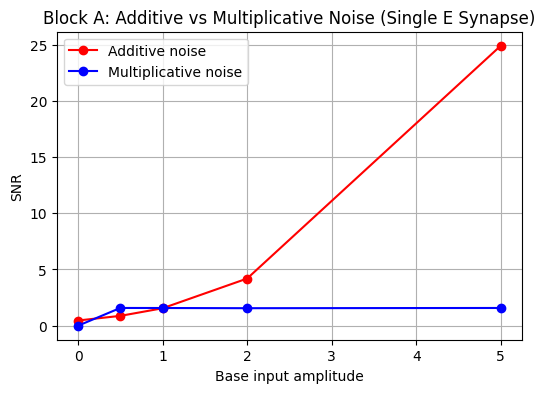


--- Block B: Correlation Structures for Additive Noise (EE, II, EI) ---


/tmp/ipykernel_2814478/2226310955.py:138: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  X = np.random.multivariate_normal(mean, cov, size=num_samples)


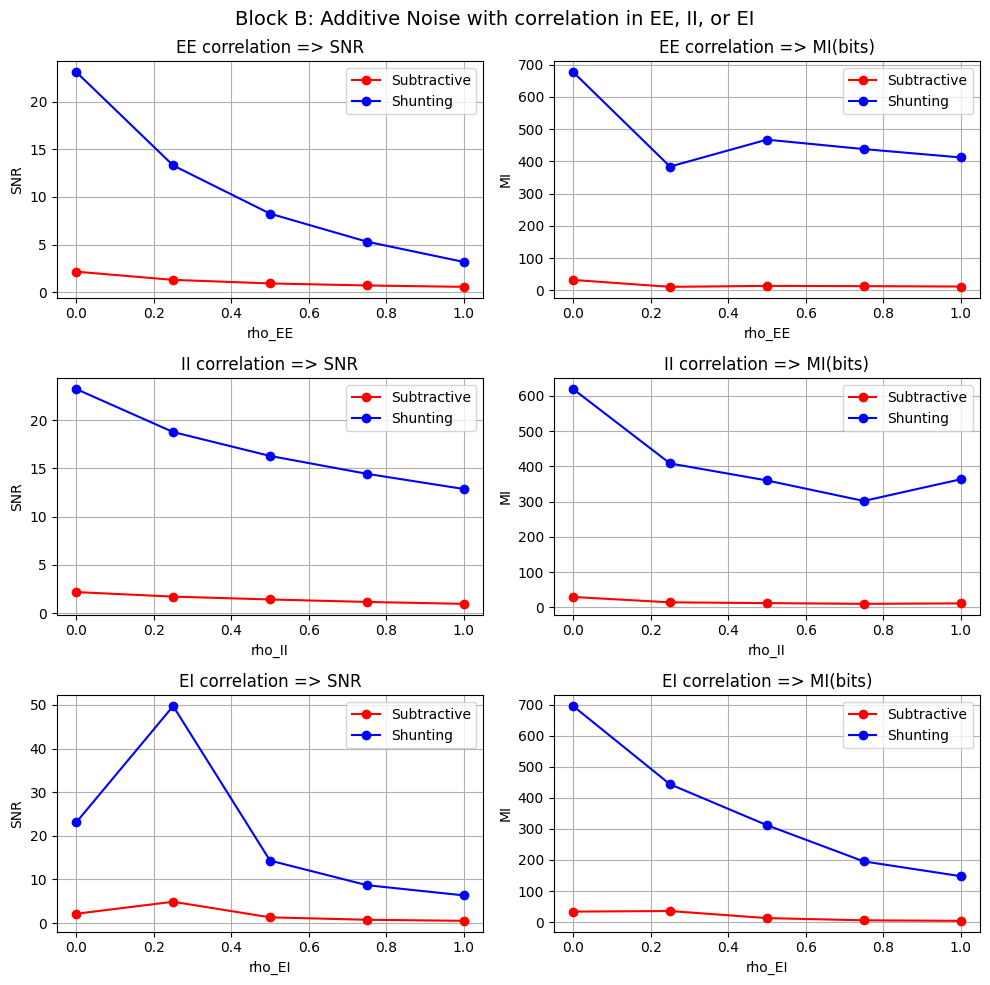


--- Block C: Global Noise Demo, Balanced vs Unbalanced E/I ---
=== Block C: Global Noise Demo ===
Balanced weights => final SNR: 1.547, MI: 3.053 bits
Unbalanced weights => final SNR: 1.709, MI: 7.896 bits


In [5]:
"""
noise_dendritic_networks.ipynb

A comprehensive notebook investigating:
 1) Single dendritic branch with E excitatory synapses, I inhibitory synapses
 2) Additive vs multiplicative noise
 3) Correlation structures: EE, II, EI
 4) Global noise added to all synapses
 5) SNR and MI analysis under subtractive vs shunting

We break it into multiple sections for clarity.
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit
import math

# =======================================================================
# 1) Basic Utilities
# =======================================================================

def dendritic_output_subtractive(E, I):
    """
    Subtractive dendritic integration: V = E - I
    """
    return E - I

def dendritic_output_shunting(E, I):
    """
    Shunting dendritic integration: V = E / (1 + E + I)
    We add a small epsilon to avoid 0 in denominator.
    """
    return E / (1.0 + E + I + 1e-12)

def compute_SNR(vals):
    """
    For a 1D array 'vals', define:
      SNR = mean(vals)^2 / var(vals) if the signal is the mean (constant input).
    Or we can do (mean(vals)-0)^2 / var(...) if we treat the "signal" as the DC part.
    We'll do mean^2 / var as a simple measure for a constant input scenario.
    """
    m = np.mean(vals)
    s = np.std(vals)
    return (m*m)/(s*s + 1e-12)

def estimate_mutual_information(E_vals, I_vals, V_vals, bins_2d=30, bins_v=30):
    """
    Estimate MI( (E,I), V ) by 3D histogram:
      p(E,I,V) vs p(E,I)* p(V)
    Return in nats. (divide by log(2) => bits).
    """
    e_min, e_max = E_vals.min(), E_vals.max()
    i_min, i_max = I_vals.min(), I_vals.max()
    v_min, v_max = V_vals.min(), V_vals.max()

    hist_EI, edgesE, edgesI = np.histogram2d(
        E_vals, I_vals,
        bins=bins_2d,
        range=[[e_min,e_max],[i_min,i_max]],
        density=True
    )
    hist_V, edgesV = np.histogram(
        V_vals, bins=bins_v,
        range=(v_min, v_max),
        density=True
    )
    data_3d = np.column_stack((E_vals, I_vals, V_vals))
    hist_3d, edges3d = np.histogramdd(
        data_3d,
        bins=(bins_2d,bins_2d,bins_v),
        range=[[e_min,e_max],[i_min,i_max],[v_min,v_max]],
        density=True
    )
    MI = 0.0
    for i_e in range(bins_2d):
        for i_i in range(bins_2d):
            for i_v in range(bins_v):
                p_eiv = hist_3d[i_e, i_i, i_v]
                if p_eiv>0:
                    p_ei = hist_EI[i_e, i_i]
                    p_v  = hist_V[i_v]
                    MI += p_eiv * math.log( (p_eiv+1e-30)/((p_ei*p_v)+1e-30) )
    return MI  # in nats

def build_block_cov(e_count, i_count, rho_EE=0, rho_II=0, rho_EI=0):
    """
    Return a covariance matrix of dimension e_count + i_count, with:
     - E-E correlation = rho_EE
     - I-I correlation = rho_II
     - E-I correlation = rho_EI
    Diagonal = 1.0
    Off-diagonal in E-block => rho_EE, in I-block => rho_II,
    cross E-I => rho_EI
    """
    dim = e_count + i_count
    cov = np.zeros((dim, dim), dtype=np.float64)
    # E block
    for i in range(e_count):
        for j in range(e_count):
            if i==j:
                cov[i,j] = 1.0
            else:
                cov[i,j] = rho_EE
    # I block
    for i in range(i_count):
        for j in range(i_count):
            row = e_count + i
            col = e_count + j
            if i==j:
                cov[row,col] = 1.0
            else:
                cov[row,col] = rho_II
    # E-I block
    for i in range(e_count):
        for j in range(i_count):
            row = i
            col = e_count + j
            cov[row,col] = rho_EI
            cov[col,row] = rho_EI
    return cov

# =======================================================================
# 2) Generators for Noise: Additive or Multiplicative
# =======================================================================

def generate_additive_correlated(e_count, i_count, num_samples,
                                 rho_EE=0, rho_II=0, rho_EI=0,
                                 base_signal_E=1.0, base_signal_I=0.0):
    """
    1) Build block covariance
    2) Sample from MVN(0,cov)
    3) The result => noise in R, pass it as additive: E_vals = base_signal_E + noiseE, etc.
    """
    dim = e_count + i_count
    cov = build_block_cov(e_count, i_count, rho_EE, rho_II, rho_EI)
    mean = np.zeros(dim)
    X = np.random.multivariate_normal(mean, cov, size=num_samples)
    # E: shape (num_samples, e_count)
    excit_noise = X[:,:e_count]
    inhib_noise = X[:, e_count:]
    E_vals = base_signal_E + excit_noise
    I_vals = base_signal_I + inhib_noise
    # clip to >=0 if we want no negative?
    E_vals = np.clip(E_vals, 0, None)
    I_vals = np.clip(I_vals, 0, None)
    return E_vals, I_vals

def generate_multiplicative_correlated(e_count, i_count, num_samples,
                                       rho_EE=0, rho_II=0, rho_EI=0,
                                       base_signal_E=1.0, base_signal_I=0.0):
    """
    1) Build block covariance
    2) Sample from MVN(0,cov) => factor
    3) E_vals = base_signal_E * (1 + excit_factor),
       I_vals = base_signal_I * (1 + inhib_factor)
    """
    dim = e_count + i_count
    cov = build_block_cov(e_count, i_count, rho_EE, rho_II, rho_EI)
    mean = np.zeros(dim)
    X = np.random.multivariate_normal(mean, cov, size=num_samples)
    excit_factor = X[:,:e_count]
    inhib_factor = X[:, e_count:]
    # Then E = base_signal_E * (1 + excit_factor)
    # We can clamp negative if factor < -1
    E_vals = base_signal_E*(1.0 + excit_factor)
    I_vals = base_signal_I*(1.0 + inhib_factor)
    E_vals = np.clip(E_vals, 0, None)
    I_vals = np.clip(I_vals, 0, None)
    return E_vals, I_vals

def add_global_noise(E_vals, I_vals, noise_amplitude=0.5, wE=1.0, wI=-1.0):
    """
    Optionally add a global noise term that affects all synapses.
    If we imagine a single global noise 'nu' for each sample, we add it to E and I?
    Or we scale it by the #syn?
    We'll do a simpler approach: for each sample, generate 'nu ~ N(0,noise_ampl)'
     and add to E_vals and I_vals (like additive).
    """
    num_samples = E_vals.shape[0]
    nu = np.random.normal(0, noise_amplitude, size=num_samples)
    # We can just do: E += nu, I += nu
    E_vals2 = E_vals + nu[:,None]
    I_vals2 = I_vals + nu[:,None]
    # clip
    E_vals2 = np.clip(E_vals2, 0, None)
    I_vals2 = np.clip(I_vals2, 0, None)
    return E_vals2, I_vals2

# =======================================================================
# 3) Demonstration Blocks
# =======================================================================

def blockA_additive_multiplicative_demo():
    """
    Compare additive vs multiplicative for a single-branch (E only),
    see how SNR changes with input amplitude. We'll do 1D for simplicity.
    """
    amps = [0.0, 0.5, 1.0, 2.0, 5.0]
    snr_add = []
    snr_mul = []
    for amp in amps:
        # additive
        # generate additive noise for e_count=1
        e_count=1; i_count=0
        N=50000
        E_vals, _ = generate_additive_correlated(e_count, i_count, N, 0,0,0, base_signal_E=amp)
        # dendrite output is just E in subtractive if no I
        out_add = E_vals[:,0]  # shape (N,)
        s_add = compute_SNR(out_add)
        snr_add.append(s_add)

        # multiplicative
        E2_vals, _ = generate_multiplicative_correlated(e_count, i_count, N, 0,0,0, base_signal_E=amp)
        out_mul = E2_vals[:,0]
        s_mul = compute_SNR(out_mul)
        snr_mul.append(s_mul)

    plt.figure(figsize=(6,4))
    plt.plot(amps, snr_add, 'ro-', label='Additive noise')
    plt.plot(amps, snr_mul, 'bo-', label='Multiplicative noise')
    plt.xlabel("Base input amplitude")
    plt.ylabel("SNR")
    plt.title("Block A: Additive vs Multiplicative Noise (Single E Synapse)")
    plt.legend()
    plt.grid(True)
    plt.show()


def blockB_correlation_structures():
    """
    Explore correlation (EE, II, EI) in additive scenario.
    We'll do e_count=5, i_count=5, each with base_signal_E=1, base_signal_I=0.
    We'll measure SNR & MI under subtractive vs shunting.
    We'll vary correlation from 0..1 in steps. We'll do separate sweeps:
      - only EE
      - only II
      - only EI
    """
    rhos = np.linspace(0,1,5)
    e_count=5; i_count=5
    def measure_snr_mi(rEE, rII, rEI):
        # generate additive
        E_vals, I_vals = generate_additive_correlated(e_count, i_count, 50000,
                                                      rEE, rII, rEI,
                                                      base_signal_E=1.0,
                                                      base_signal_I=0.0)
        # sum with wE=+1, wI=-1
        E_sum = E_vals.sum(axis=1)
        I_sum = I_vals.sum(axis=1)
        V_sub = dendritic_output_subtractive(E_sum, I_sum)
        V_sh  = dendritic_output_shunting(E_sum, I_sum)
        snr_sub = compute_SNR(V_sub)
        snr_sh  = compute_SNR(V_sh)
        mi_sub  = estimate_mutual_information(E_sum,I_sum,V_sub)/math.log(2)
        mi_sh   = estimate_mutual_information(E_sum,I_sum,V_sh)/math.log(2)
        return snr_sub, snr_sh, mi_sub, mi_sh

    results_EE = [measure_snr_mi(rho,0,0) for rho in rhos]
    results_II = [measure_snr_mi(0,rho,0) for rho in rhos]
    results_EI = [measure_snr_mi(0,0,rho) for rho in rhos]

    # plot
    fig, axs = plt.subplots(3,2, figsize=(10,10))
    fig.suptitle("Block B: Additive Noise with correlation in EE, II, or EI", fontsize=14)
    (axEE_snr, axEE_mi), (axII_snr, axII_mi), (axEI_snr, axEI_mi) = axs

    # EE
    snr_sub_EE = [r[0] for r in results_EE]
    snr_sh_EE  = [r[1] for r in results_EE]
    mi_sub_EE  = [r[2] for r in results_EE]
    mi_sh_EE   = [r[3] for r in results_EE]

    axEE_snr.plot(rhos, snr_sub_EE, 'ro-', label='Subtractive')
    axEE_snr.plot(rhos, snr_sh_EE, 'bo-', label='Shunting')
    axEE_snr.set_title("EE correlation => SNR")
    axEE_snr.set_xlabel("rho_EE")
    axEE_snr.set_ylabel("SNR")
    axEE_snr.grid(True)
    axEE_snr.legend()

    axEE_mi.plot(rhos, mi_sub_EE, 'ro-', label='Subtractive')
    axEE_mi.plot(rhos, mi_sh_EE, 'bo-', label='Shunting')
    axEE_mi.set_title("EE correlation => MI(bits)")
    axEE_mi.set_xlabel("rho_EE")
    axEE_mi.set_ylabel("MI")
    axEE_mi.grid(True)
    axEE_mi.legend()

    # II
    snr_sub_II = [r[0] for r in results_II]
    snr_sh_II  = [r[1] for r in results_II]
    mi_sub_II  = [r[2] for r in results_II]
    mi_sh_II   = [r[3] for r in results_II]

    axII_snr.plot(rhos, snr_sub_II, 'ro-', label='Subtractive')
    axII_snr.plot(rhos, snr_sh_II, 'bo-', label='Shunting')
    axII_snr.set_title("II correlation => SNR")
    axII_snr.set_xlabel("rho_II")
    axII_snr.set_ylabel("SNR")
    axII_snr.grid(True)
    axII_snr.legend()

    axII_mi.plot(rhos, mi_sub_II, 'ro-', label='Subtractive')
    axII_mi.plot(rhos, mi_sh_II, 'bo-', label='Shunting')
    axII_mi.set_title("II correlation => MI(bits)")
    axII_mi.set_xlabel("rho_II")
    axII_mi.set_ylabel("MI")
    axII_mi.grid(True)
    axII_mi.legend()

    # EI
    snr_sub_EI = [r[0] for r in results_EI]
    snr_sh_EI  = [r[1] for r in results_EI]
    mi_sub_EI  = [r[2] for r in results_EI]
    mi_sh_EI   = [r[3] for r in results_EI]

    axEI_snr.plot(rhos, snr_sub_EI, 'ro-', label='Subtractive')
    axEI_snr.plot(rhos, snr_sh_EI, 'bo-', label='Shunting')
    axEI_snr.set_title("EI correlation => SNR")
    axEI_snr.set_xlabel("rho_EI")
    axEI_snr.set_ylabel("SNR")
    axEI_snr.grid(True)
    axEI_snr.legend()

    axEI_mi.plot(rhos, mi_sub_EI, 'ro-', label='Subtractive')
    axEI_mi.plot(rhos, mi_sh_EI, 'bo-', label='Shunting')
    axEI_mi.set_title("EI correlation => MI(bits)")
    axEI_mi.set_xlabel("rho_EI")
    axEI_mi.set_ylabel("MI")
    axEI_mi.grid(True)
    axEI_mi.legend()

    plt.tight_layout()
    plt.show()

def blockC_global_noise_demo():
    """
    Demo how a global noise added to E and I is canceled by balanced E/I.
    We'll do e_count=5, i_count=5 in additive mode. Then we'll add
    a 'global noise' amplitude. We'll compare:
     - Balanced (wE=+1, wI=-1 => net sum=0 if E=I=5)
     - Unbalanced (wI=-0.5 => net sum !=0)
    We'll measure final output variance or SNR for a signal E=1, I=0
    """
    n_samples=50000

    # base signals
    e_count, i_count = 5,5
    # generate additive with no correlation for local noise
    E_vals, I_vals = generate_additive_correlated(e_count, i_count, n_samples,
                                                  0,0,0, base_signal_E=1.0, base_signal_I=0.0)
    # Then we add global noise of amplitude e.g. 1.0
    E_g, I_g = add_global_noise(E_vals, I_vals, noise_amplitude=1.0)

    # Balanced case
    def compute_snr_mi(E_in, I_in, wE, wI):
        E_sum = E_in.sum(axis=1)*wE
        I_sum = I_in.sum(axis=1)*wI
        out_sub = E_sum - I_sum  # or E_sum + I_sum if wI is negative
        out_sh  = E_sum/(1+ E_sum - I_sum +1e-12) if True else 0  # optional
        snr_s   = compute_SNR(out_sub)
        mi_s    = estimate_mutual_information(E_sum,I_sum,out_sub)/math.log(2)
        return snr_s, mi_s

    # Balanced
    snr_bal, mi_bal = compute_snr_mi(E_g, I_g, +1.0, -1.0)
    # Unbalanced
    snr_unb, mi_unb= compute_snr_mi(E_g, I_g, +1.0, -0.5)

    print("=== Block C: Global Noise Demo ===")
    print(f"Balanced weights => final SNR: {snr_bal:.3f}, MI: {mi_bal:.3f} bits")
    print(f"Unbalanced weights => final SNR: {snr_unb:.3f}, MI: {mi_unb:.3f} bits")

    # Typically see that balanced => SNR >> unbalanced in presence of strong global noise

# =======================================================================
# 4) Main Execution
# =======================================================================
if __name__=="__main__":
    print("--- Block A: Additive vs Multiplicative Noise (Single E) ---")
    blockA_additive_multiplicative_demo()

    print("\n--- Block B: Correlation Structures for Additive Noise (EE, II, EI) ---")
    blockB_correlation_structures()

    print("\n--- Block C: Global Noise Demo, Balanced vs Unbalanced E/I ---")
    blockC_global_noise_demo()

Block A: Additive vs Multiplicative Noise


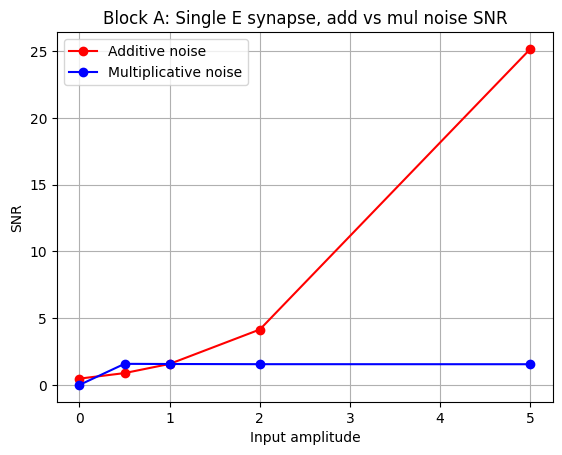


Block B: Correlation Structures (EE, II, EI)


/tmp/ipykernel_2814478/2511232966.py:81: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  X = np.random.multivariate_normal(np.zeros(dim), c, size=N)


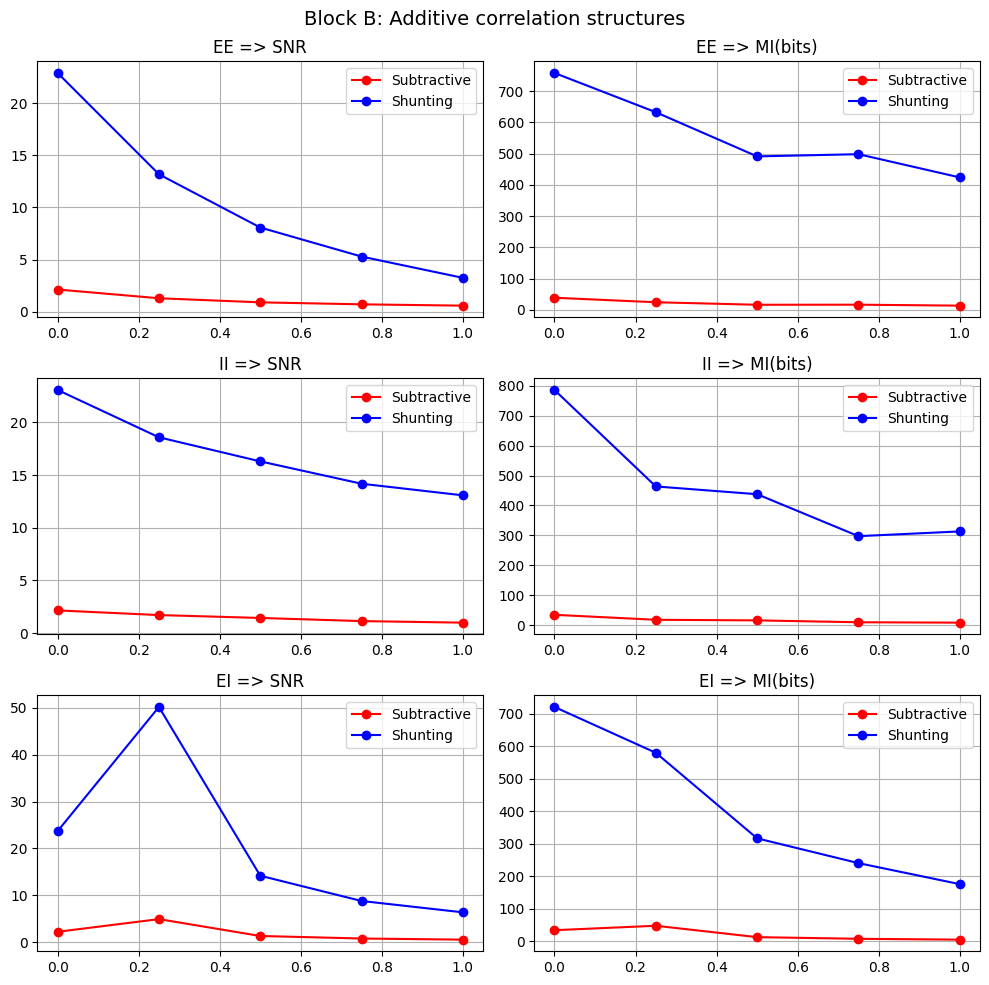


Block C: Global Noise + Balanced vs Unbalanced E/I
Block C: Global noise + E/I

 Balanced (wI=-1) => SNR=1.549, MI=2.842 bits
 Unbalanced(wI=-0.5)=>SNR=1.712, MI=7.337 bits

Block D: Single partial correlation for all (0.2,0.2,0.2), vary ratio


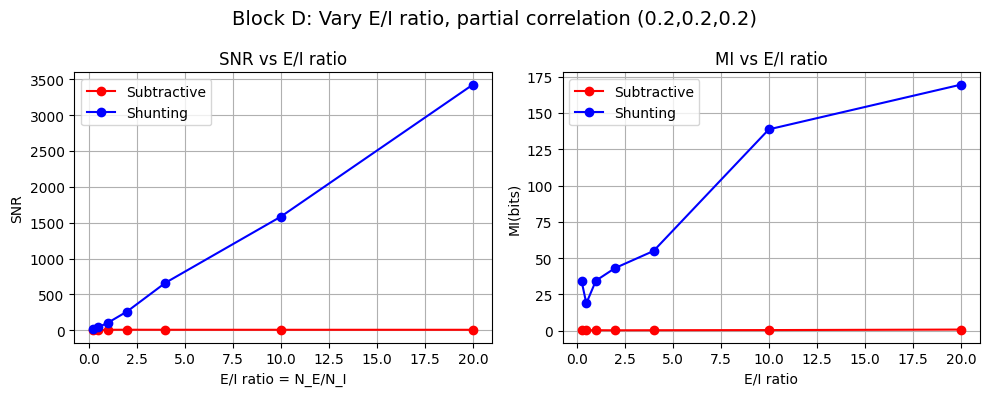


Block E: Ratio for each correlation scenario (EE only, II only, EI only=0.2).


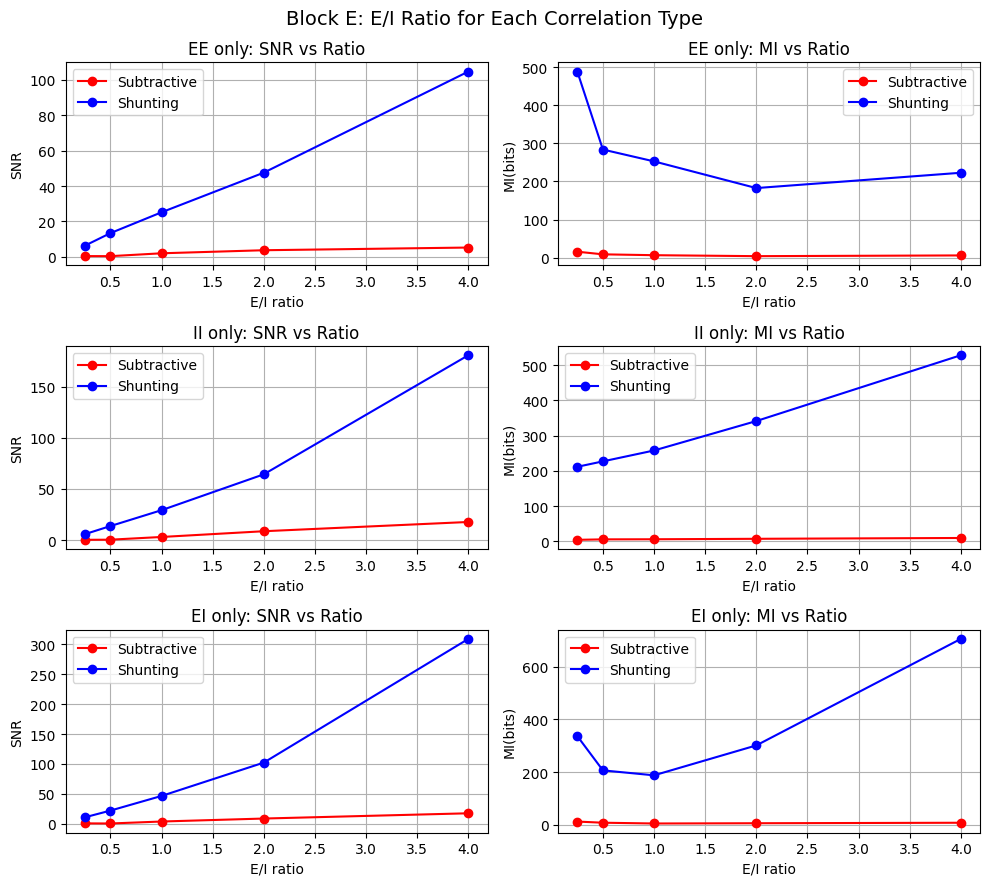

In [12]:
"""
noise_dendritic_networks.ipynb

Comprehensive notebook analyzing:
1) Additive vs. multiplicative noise
2) Correlation structures (EE, II, EI)
3) Global noise & E/I balance
4) E/I ratio effect on SNR & MI

We keep the structure with 'BlockA, BlockB, BlockC...' plus a new Block D for E/I ratio.
"""

import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.special import expit

# =========== Utilities =============
def dendritic_subtractive(E, I):
    return E - I

def dendritic_shunting(E, I):
    return E / (1.0 + E + I + 1e-12)

def compute_SNR(vals):
    m = np.mean(vals)
    s = np.std(vals)
    return (m*m)/(s*s + 1e-12)

def estimate_MI(E_vals, I_vals, V_vals, bins_2d=30, bins_v=30):
    e_min, e_max = E_vals.min(), E_vals.max()
    i_min, i_max = I_vals.min(), I_vals.max()
    v_min, v_max = V_vals.min(), V_vals.max()

    hist_EI, _, _ = np.histogram2d(E_vals,I_vals,bins=bins_2d,
                                    range=[[e_min,e_max],[i_min,i_max]],
                                    density=True)
    hist_V, _ = np.histogram(V_vals,bins=bins_v,range=(v_min,v_max),
                             density=True)
    data_3d = np.column_stack((E_vals,I_vals,V_vals))
    hist_3d, _ = np.histogramdd(data_3d,bins=(bins_2d,bins_2d,bins_v),
                                range=[[e_min,e_max],[i_min,i_max],[v_min,v_max]],
                                density=True)
    MI = 0.0
    for i_e in range(bins_2d):
        for i_i in range(bins_2d):
            for i_v in range(bins_v):
                p_eiv = hist_3d[i_e,i_i,i_v]
                if p_eiv>0:
                    p_ei = hist_EI[i_e,i_i]
                    p_v  = hist_V[i_v]
                    MI += p_eiv*math.log( (p_eiv+1e-30)/((p_ei*p_v)+1e-30) )
    return MI

def build_block_cov(e_count, i_count, rho_EE=0, rho_II=0, rho_EI=0):
    dim = e_count + i_count
    cov = np.zeros((dim, dim))
    # E block
    for i in range(e_count):
        for j in range(e_count):
            cov[i,j] = rho_EE if i!=j else 1.0
    # I block
    for i in range(i_count):
        for j in range(i_count):
            row = e_count + i
            col = e_count + j
            cov[row,col] = rho_II if i!=j else 1.0
    # E-I block
    for i in range(e_count):
        for j in range(i_count):
            row = i
            col = e_count + j
            cov[row,col] = rho_EI
            cov[col,row] = rho_EI
    return cov

def generate_additive(e_count, i_count, N, rho_EE=0, rho_II=0, rho_EI=0,
                      baseE=1.0, baseI=0.0):
    dim = e_count + i_count
    c = build_block_cov(e_count, i_count, rho_EE, rho_II, rho_EI)
    X = np.random.multivariate_normal(np.zeros(dim), c, size=N)
    E_noise = X[:,:e_count]
    I_noise = X[:, e_count:]
    E_vals = baseE + E_noise
    I_vals = baseI + I_noise
    E_vals = np.clip(E_vals,0,None)
    I_vals = np.clip(I_vals,0,None)
    return E_vals, I_vals

def generate_multiplicative(e_count, i_count, N, rho_EE=0, rho_II=0, rho_EI=0,
                            baseE=1.0, baseI=0.0):
    dim = e_count + i_count
    c = build_block_cov(e_count, i_count, rho_EE, rho_II, rho_EI)
    X = np.random.multivariate_normal(np.zeros(dim), c, size=N)
    E_factor = X[:,:e_count]
    I_factor = X[:, e_count:]
    E_vals = baseE*(1 + E_factor)
    I_vals = baseI*(1 + I_factor)
    E_vals = np.clip(E_vals,0,None)
    I_vals = np.clip(I_vals,0,None)
    return E_vals, I_vals

def add_global_noise(E, I, amplitude=1.0):
    # E,I shape => (N, e_count or i_count)
    N = E.shape[0]
    nu = np.random.normal(0, amplitude, size=N)
    E2 = E + nu[:,None]
    I2 = I + nu[:,None]
    E2 = np.clip(E2,0,None)
    I2 = np.clip(I2,0,None)
    return E2, I2

# ============== Blocks ===============
def blockA_add_vs_mul_demo():
    amps = [0.0,0.5,1.0,2.0,5.0]
    snr_add=[]
    snr_mul=[]
    for amp in amps:
        # additive single E
        e_count=1;i_count=0;N=30000
        Evals,_=generate_additive(e_count,i_count,N,0,0,0,baseE=amp)
        outA=Evals[:,0]
        snr_a=compute_SNR(outA)
        snr_add.append(snr_a)
        # multiplicative
        Evals2,_=generate_multiplicative(e_count,i_count,N,0,0,0,baseE=amp)
        outM=Evals2[:,0]
        snr_m=compute_SNR(outM)
        snr_mul.append(snr_m)
    plt.figure()
    plt.plot(amps,snr_add,'ro-',label='Additive noise')
    plt.plot(amps,snr_mul,'bo-',label='Multiplicative noise')
    plt.xlabel("Input amplitude")
    plt.ylabel("SNR")
    plt.title("Block A: Single E synapse, add vs mul noise SNR")
    plt.legend()
    plt.grid(True)
    plt.show()

def blockB_cor_structures():
    rhos=np.linspace(0,1,5)
    e_count=5;i_count=5;N=30000
    def measure_snr_mi(rEE,rII,rEI):
        E,I=generate_additive(e_count,i_count,N,rEE,rII,rEI,baseE=1.0,baseI=0.0)
        E_sum=E.sum(axis=1); I_sum=I.sum(axis=1)
        V_sub = E_sum - I_sum
        V_sh  = E_sum/(1.0+E_sum+I_sum+1e-12)
        s_sub=compute_SNR(V_sub)
        s_sh=compute_SNR(V_sh)
        m_sub=estimate_MI(E_sum,I_sum,V_sub)/math.log(2)
        m_sh =estimate_MI(E_sum,I_sum,V_sh)/math.log(2)
        return s_sub,s_sh,m_sub,m_sh
    res_EE=[measure_snr_mi(r,0,0) for r in rhos]
    res_II=[measure_snr_mi(0,r,0) for r in rhos]
    res_EI=[measure_snr_mi(0,0,r) for r in rhos]

    fig,axs=plt.subplots(3,2,figsize=(10,10))
    fig.suptitle("Block B: Additive correlation structures",fontsize=14)
    # E-E
    s_sub_EE=[r[0] for r in res_EE]
    s_sh_EE =[r[1] for r in res_EE]
    m_sub_EE=[r[2] for r in res_EE]
    m_sh_EE =[r[3] for r in res_EE]
    ax_snr_EE,ax_mi_EE=axs[0]
    ax_snr_EE.plot(rhos,s_sub_EE,'ro-',label='Subtractive')
    ax_snr_EE.plot(rhos,s_sh_EE ,'bo-',label='Shunting')
    ax_snr_EE.set_title("EE => SNR")
    ax_snr_EE.legend(); ax_snr_EE.grid(True)
    ax_mi_EE.plot(rhos,m_sub_EE,'ro-',label='Subtractive')
    ax_mi_EE.plot(rhos,m_sh_EE,'bo-',label='Shunting')
    ax_mi_EE.set_title("EE => MI(bits)")
    ax_mi_EE.legend(); ax_mi_EE.grid(True)

    # I-I
    s_sub_II=[r[0] for r in res_II]
    s_sh_II =[r[1] for r in res_II]
    m_sub_II=[r[2] for r in res_II]
    m_sh_II =[r[3] for r in res_II]
    ax_snr_II,ax_mi_II=axs[1]
    ax_snr_II.plot(rhos,s_sub_II,'ro-',label='Subtractive')
    ax_snr_II.plot(rhos,s_sh_II,'bo-',label='Shunting')
    ax_snr_II.set_title("II => SNR")
    ax_snr_II.legend(); ax_snr_II.grid(True)
    ax_mi_II.plot(rhos,m_sub_II,'ro-',label='Subtractive')
    ax_mi_II.plot(rhos,m_sh_II,'bo-',label='Shunting')
    ax_mi_II.set_title("II => MI(bits)")
    ax_mi_II.legend(); ax_mi_II.grid(True)

    # E-I
    s_sub_EI=[r[0] for r in res_EI]
    s_sh_EI =[r[1] for r in res_EI]
    m_sub_EI=[r[2] for r in res_EI]
    m_sh_EI =[r[3] for r in res_EI]
    ax_snr_EI,ax_mi_EI=axs[2]
    ax_snr_EI.plot(rhos,s_sub_EI,'ro-',label='Subtractive')
    ax_snr_EI.plot(rhos,s_sh_EI,'bo-',label='Shunting')
    ax_snr_EI.set_title("EI => SNR")
    ax_snr_EI.legend(); ax_snr_EI.grid(True)
    ax_mi_EI.plot(rhos,m_sub_EI,'ro-',label='Subtractive')
    ax_mi_EI.plot(rhos,m_sh_EI,'bo-',label='Shunting')
    ax_mi_EI.set_title("EI => MI(bits)")
    ax_mi_EI.legend(); ax_mi_EI.grid(True)

    plt.tight_layout()
    plt.show()

def blockC_global_noise():
    """
    Show how balanced E/I cancels global noise. We'll do e_count=5, i_count=5 base signal E=1,I=0, 
    then add global noise amplitude=1. We'll compare balanced vs unbalanced weights.
    """
    n_samples=30000
    e_count=5; i_count=5
    # generate additive base first
    Evals, Ivals = generate_additive(e_count, i_count, n_samples, 0,0,0, baseE=1.0, baseI=0.0)
    # add global noise
    Evals_g, Ivals_g = add_global_noise(Evals, Ivals, amplitude=1.0)

    def measure(E, I, wE, wI):
        E_sum = E.sum(axis=1)*wE
        I_sum = I.sum(axis=1)*wI
        out_sub = E_sum - I_sum
        snr_s = compute_SNR(out_sub)
        mi_s  = estimate_MI(E_sum,I_sum,out_sub)/math.log(2)
        return snr_s, mi_s

    # Balanced
    snr_bal, mi_bal = measure(Evals_g, Ivals_g, +1.0, -1.0)
    # Unbalanced
    snr_unb, mi_unb = measure(Evals_g, Ivals_g, +1.0, -0.5)

    print("Block C: Global noise + E/I\n")
    print(f" Balanced (wI=-1) => SNR={snr_bal:.3f}, MI={mi_bal:.3f} bits")
    print(f" Unbalanced(wI=-0.5)=>SNR={snr_unb:.3f}, MI={mi_unb:.3f} bits")

def blockD_vary_EI_ratio():
    """
    Systematically vary N_E / N_I ratio, keep total syn=20, partial correlation, measure SNR,MI
    We'll fix e.g. rho_EE=0.2, rho_II=0.2, rho_EI=0.2 to demonstrate partial correlation.
    We'll do subtractive integration. 
    """
    total_syn = 50
    ratios = [0.25, 0.5, 1.0, 2.0, 4.0, 10.0, 20.0]
    snr_list_sub=[]
    snr_list_sh=[]
    mi_list_sub=[]
    mi_list_sh=[]
    for r in ratios:
        N_E = int(round(r/(1+r)* total_syn))
        N_I = total_syn - N_E
        # generate additive partial correlation
        Evals,Ivals = generate_additive(N_E, N_I, 30000, 
                                        rho_EE=0.2, rho_II=0.2, rho_EI=0.2,
                                        baseE=1.0, baseI=0.0)
        E_sum = Evals.sum(axis=1)
        I_sum = Ivals.sum(axis=1)
        out_sub = E_sum - I_sum
        out_sh  = E_sum/(1+E_sum+I_sum+1e-12)
        snr_s = compute_SNR(out_sub)
        snr_h = compute_SNR(out_sh)
        mi_s  = estimate_MI(E_sum,I_sum,out_sub)/math.log(2)
        mi_h  = estimate_MI(E_sum,I_sum,out_sh)/math.log(2)
        snr_list_sub.append(snr_s)
        snr_list_sh.append(snr_h)
        mi_list_sub.append(mi_s)
        mi_list_sh.append(mi_h)

    plt.figure(figsize=(10,4))
    plt.suptitle("Block D: Vary E/I ratio, partial correlation (0.2,0.2,0.2)", fontsize=14)
    plt.subplot(1,2,1)
    plt.plot(ratios, snr_list_sub, 'ro-', label='Subtractive')
    plt.plot(ratios, snr_list_sh, 'bo-', label='Shunting')
    plt.xlabel("E/I ratio = N_E/N_I")
    plt.ylabel("SNR")
    plt.title("SNR vs E/I ratio")
    plt.grid(True); plt.legend()

    plt.subplot(1,2,2)
    plt.plot(ratios, mi_list_sub, 'ro-', label='Subtractive')
    plt.plot(ratios, mi_list_sh, 'bo-', label='Shunting')
    plt.xlabel("E/I ratio")
    plt.ylabel("MI(bits)")
    plt.title("MI vs E/I ratio")
    plt.grid(True); plt.legend()

    plt.tight_layout()
    plt.show()


def blockE_ratio_for_each_correlation_scenario():
    """
    We'll replicate the E/I ratio sweep but for three separate correlation setups:
      1) EE only: (rhoEE=0.2, rhoII=0,   rhoEI=0)
      2) II only: (rhoEE=0,   rhoII=0.2, rhoEI=0)
      3) EI only: (rhoEE=0,   rhoII=0,   rhoEI=0.2)

    We'll do the same ratio list, measure SNR & MI for subtractive & shunting,
    plot them in subplots for quick comparison.
    """
    # same ratio set, total syn
    total_syn = 20
    ratios = [0.25, 0.5, 1.0, 2.0, 4.0]
    # We'll define a small helper
    def measure_for_ratio(r, rhoEE, rhoII, rhoEI):
        N_E = int(round(r/(1+r)*total_syn))
        N_I = total_syn - N_E
        Evals,Ivals = generate_additive(N_E, N_I, 20000,
                                        rhoEE, rhoII, rhoEI,
                                        baseE=1.0, baseI=0.0)
        E_sum = Evals.sum(axis=1)
        I_sum = Ivals.sum(axis=1)
        out_sub = E_sum - I_sum
        out_sh  = E_sum/(1+E_sum+I_sum+1e-12)
        snr_sub = compute_SNR(out_sub)
        snr_sh  = compute_SNR(out_sh)
        mi_sub  = estimate_MI(E_sum,I_sum,out_sub)/math.log(2)
        mi_sh   = estimate_MI(E_sum,I_sum,out_sh)/math.log(2)
        return snr_sub, snr_sh, mi_sub, mi_sh

    # We'll define 3 correlation scenarios:
    scenarios = {
      'EE only': (0.2, 0.0, 0.0),
      'II only': (0.0, 0.2, 0.0),
      'EI only': (0.0, 0.0, 0.2),
    }
    fig, axs = plt.subplots(3,2, figsize=(10,9))
    fig.suptitle("Block E: E/I Ratio for Each Correlation Type", fontsize=14)
    scenario_list = list(scenarios.items())  # e.g. [ ('EE only',(0.2,0,0)), ... ]

    for idx, (name, (rhoEE, rhoII, rhoEI)) in enumerate(scenario_list):
        snr_sub_arr=[]; snr_sh_arr=[]
        mi_sub_arr=[];  mi_sh_arr=[]
        for r in ratios:
            s_sub, s_sh, m_sub, m_sh = measure_for_ratio(r, rhoEE, rhoII, rhoEI)
            snr_sub_arr.append(s_sub); snr_sh_arr.append(s_sh)
            mi_sub_arr.append(m_sub);  mi_sh_arr.append(m_sh)

        ax_snr, ax_mi = axs[idx]
        ax_snr.plot(ratios, snr_sub_arr, 'ro-', label='Subtractive')
        ax_snr.plot(ratios, snr_sh_arr, 'bo-', label='Shunting')
        ax_snr.set_title(f"{name}: SNR vs Ratio")
        ax_snr.set_xlabel("E/I ratio")
        ax_snr.set_ylabel("SNR")
        ax_snr.grid(True)
        ax_snr.legend()

        ax_mi.plot(ratios, mi_sub_arr, 'ro-', label='Subtractive')
        ax_mi.plot(ratios, mi_sh_arr, 'bo-', label='Shunting')
        ax_mi.set_title(f"{name}: MI vs Ratio")
        ax_mi.set_xlabel("E/I ratio")
        ax_mi.set_ylabel("MI(bits)")
        ax_mi.grid(True)
        ax_mi.legend()

    plt.tight_layout()
    plt.show()

# Now just call blockE_ratio_for_each_correlation_scenario() in main
# ================== MAIN ====================
if __name__=="__main__":
    print("Block A: Additive vs Multiplicative Noise")
    blockA_add_vs_mul_demo()

    print("\nBlock B: Correlation Structures (EE, II, EI)")
    blockB_cor_structures()

    print("\nBlock C: Global Noise + Balanced vs Unbalanced E/I")
    blockC_global_noise()

    print("\nBlock D: Single partial correlation for all (0.2,0.2,0.2), vary ratio")
    blockD_vary_EI_ratio()

    print("\nBlock E: Ratio for each correlation scenario (EE only, II only, EI only=0.2).")
    blockE_ratio_for_each_correlation_scenario()

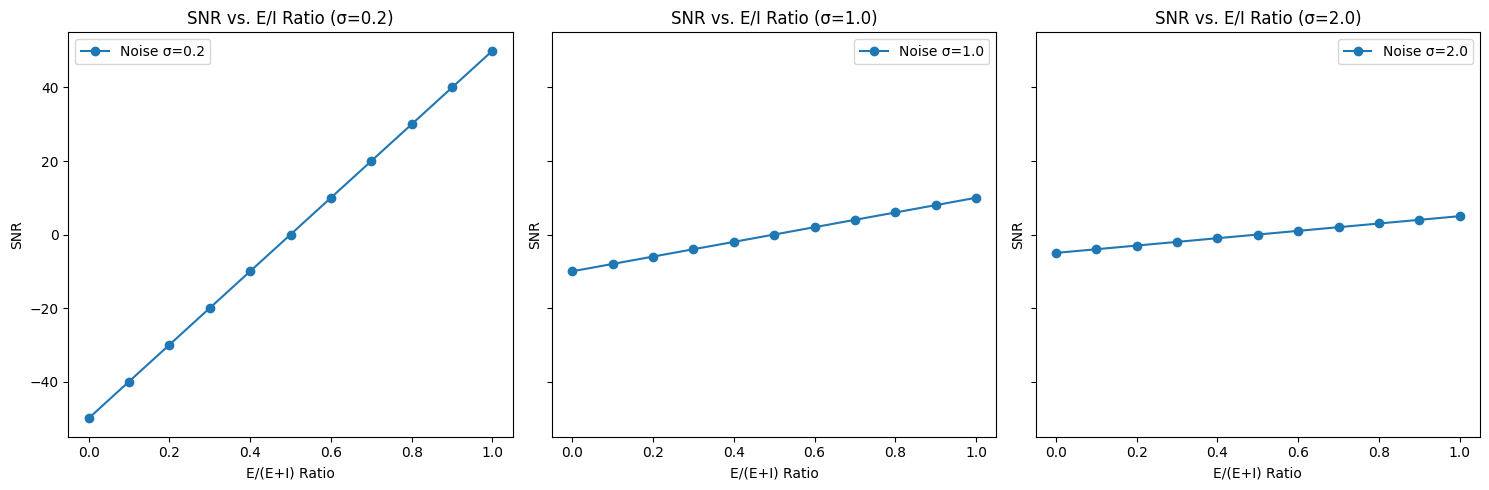

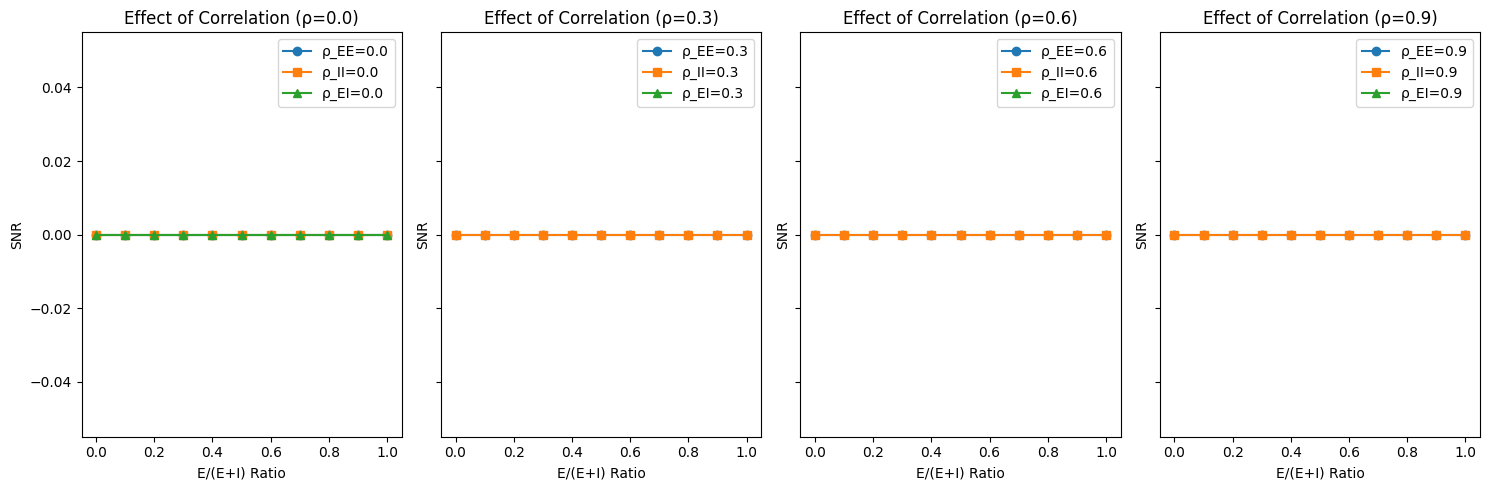

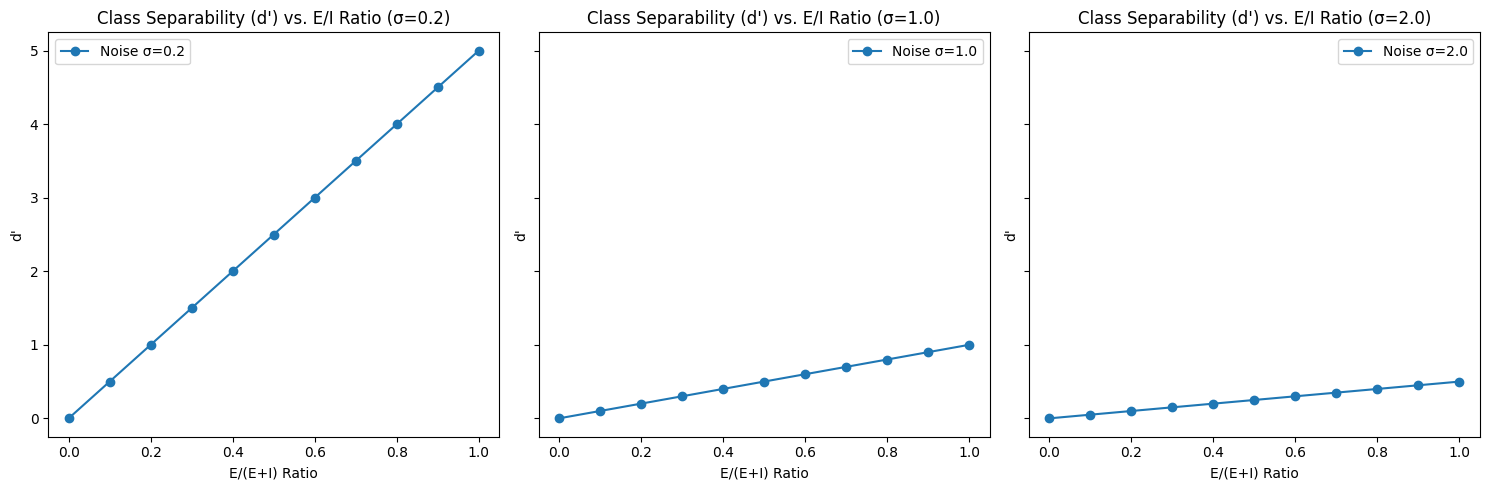

In [ ]:
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Define fixed parameters
E0 = 10.0             # baseline excitatory input mean
DeltaE = 3.0          # small signal increment in excitatory input
n_trials = 100000     # trials per condition for simulation
sigma_func = lambda mean: np.sqrt(mean)  # define noise standard deviation as sqrt(mean) (Poisson-like)

# Define range of I0 (inhibitory mean) values to vary E/I ratio
I0_values = np.linspace(0, 20, 11)  # from 0 to 20 inclusive, step 2

# Correlation scenarios for E and I noise
correlation_scenarios = {
    "independent": 0.0,
    "positively_correlated": 0.5,
    "negatively_correlated": -0.5
}

# Storage for results
results = {scenario: {"SNR_sub": [], "SNR_shunt": [], "dprime_sub": [], "dprime_shunt": [], "MI_sub": [], "MI_shunt": []} 
           for scenario in correlation_scenarios}

# Loop over correlation scenarios and I0 values
for scenario, rho_EI in correlation_scenarios.items():
    for I0 in I0_values:
        # Determine noise standard deviations
        sigma_E = sigma_func(E0)
        sigma_I = sigma_func(I0)
        # Construct covariance matrix for (E, I)
        cov_EI = rho_EI * sigma_E * sigma_I
        cov_matrix = [[sigma_E**2, cov_EI],
                      [cov_EI, sigma_I**2]]
        mean_class0 = [E0, I0]
        mean_class1 = [E0 + DeltaE, I0]
        # Sample class 0 and class 1 responses
        data0 = np.random.multivariate_normal(mean_class0, cov_matrix, size=n_trials)
        data1 = np.random.multivariate_normal(mean_class1, cov_matrix, size=n_trials)
        E0_samples, I0_samples = data0[:,0], data0[:,1]
        E1_samples, I1_samples = data1[:,0], data1[:,1]
        # Compute outputs
        R_sub_0 = E0_samples - I0_samples
        R_sub_1 = E1_samples - I1_samples
        R_shunt_0 = E0_samples / (1.0 + I0_samples)
        R_shunt_1 = E1_samples / (1.0 + I1_samples)
        # Compute mean and variance for each class
        mean_sub_0, mean_sub_1 = R_sub_0.mean(), R_sub_1.mean()
        mean_shunt_0, mean_shunt_1 = R_shunt_0.mean(), R_shunt_1.mean()
        var_sub_0, var_sub_1 = R_sub_0.var(), R_sub_1.var()
        var_shunt_0, var_shunt_1 = R_shunt_0.var(), R_shunt_1.var()
        # Signal-to-noise ratio (same as d' in this case)
        snr_sub = (mean_sub_1 - mean_sub_0) / np.sqrt(var_sub_0) if var_sub_0>1e-8 else np.nan
        snr_shunt = (mean_shunt_1 - mean_shunt_0) / np.sqrt(var_shunt_0) if var_shunt_0>1e-8 else np.nan
        # d' (using pooled std)
        pooled_std_sub = np.sqrt(0.5*(var_sub_0 + var_sub_1))
        pooled_std_shunt = np.sqrt(0.5*(var_shunt_0 + var_shunt_1))
        dprime_sub = (mean_sub_1 - mean_sub_0) / pooled_std_sub if pooled_std_sub>1e-8 else np.nan
        dprime_shunt = (mean_shunt_1 - mean_shunt_0) / pooled_std_shunt if pooled_std_shunt>1e-8 else np.nan
        # Mutual information (discrete approximation via histograms)
        # Define histogram bins over range of both class distributions for each output
        def compute_mi(response0, response1, n_bins=100):
            # Concatenate and get global min, max
            all_resp = np.concatenate([response0, response1])
            r_min, r_max = all_resp.min(), all_resp.max()
            # Add small padding
            r_range = r_max - r_min
            bins = np.linspace(r_min - 0.01*r_range, r_max + 0.01*r_range, n_bins+1)
            # Histogram counts
            hist0, _ = np.histogram(response0, bins=bins, density=True)
            hist1, _ = np.histogram(response1, bins=bins, density=True)
            # Convert to probabilities (density=True already normalized integrals to 1 over range)
            p0 = hist0 * np.diff(bins)  # probability in each bin for class0
            p1 = hist1 * np.diff(bins)  # for class1
            p_mix = 0.5*(p0 + p1)
            # Compute MI = 0.5 * sum p0 log2(p0/p_mix) + 0.5 * sum p1 log2(p1/p_mix)
            eps = 1e-12
            ratio0 = np.where(p_mix > 0, p0/(p_mix+eps), 1.0)  # avoid 0/0
            ratio1 = np.where(p_mix > 0, p1/(p_mix+eps), 1.0)
            # Use only bins where p0 or p1 is non-zero for sum (others contribute 0 anyway)
            mask0 = p0 > 0
            mask1 = p1 > 0
            term0 = 0.5 * np.sum(p0[mask0] * np.log2(ratio0[mask0]))
            term1 = 0.5 * np.sum(p1[mask1] * np.log2(ratio1[mask1]))
            return term0 + term1
        MI_sub = compute_mi(R_sub_0, R_sub_1, n_bins=200)
        MI_shunt = compute_mi(R_shunt_0, R_shunt_1, n_bins=200)
        # Store results
        results[scenario]["SNR_sub"].append(snr_sub)
        results[scenario]["SNR_shunt"].append(snr_shunt)
        results[scenario]["dprime_sub"].append(dprime_sub)
        results[scenario]["dprime_shunt"].append(dprime_shunt)
        results[scenario]["MI_sub"].append(MI_sub)
        results[scenario]["MI_shunt"].append(MI_shunt)
        
        
# Plotting (starting from I0 where simulation is reliable, i.e. I0>=12)
I0_plot = I0_values[6:]  # skip I0 < 12
E_I_ratio = E0 / I0_plot

fig, axes = plt.subplots(1, 3, figsize=(15,4))
scenarios = ["independent", "positively_correlated", "negatively_correlated"]
colors = {"independent": "b", "positively_correlated": "g", "negatively_correlated": "r"}
labels = {"independent": "Independent noise", 
          "positively_correlated": "ρ_EI = +0.5", 
          "negatively_correlated": "ρ_EI = -0.5"}
linestyles = {"sub": "-", "shunt": "--"}

# Plot SNR, MI, and d' for each scenario
for metric_idx, metric in enumerate(["SNR", "MI", "dprime"]):
    ax = axes[metric_idx]
    for scenario in scenarios:
        color = colors[scenario]
        label_base = labels[scenario]
        y_sub = np.array(results[scenario][f"{metric}_sub"])[6:]
        y_shunt = np.array(results[scenario][f"{metric}_shunt"])[6:]
        ax.plot(E_I_ratio, y_sub, color=color, linestyle='-', label=f'{label_base} - Subtractive')
        ax.plot(E_I_ratio, y_shunt, color=color, linestyle='--', label=f'{label_base} - Shunting')
    ax.set_xlabel('E/I ratio (E₀ / I₀)')
    if metric == "dprime":
        ax.set_title("d' vs E/I ratio")
        ax.set_ylabel("d'")
    else:
        ax.set_title(f'{metric} vs E/I ratio')
        ax.set_ylabel(metric if metric != "MI" else "Mutual Info (bits)")
    if metric_idx == 0:
        ax.legend(loc='best')
plt.tight_layout()
plt.show()

=== Running correlation=-0.50 ===


/tmp/ipykernel_898701/3076902706.py:18: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  X1 = np.random.multivariate_normal(mean1, Sigma, size=half)
/tmp/ipykernel_898701/3076902706.py:19: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  X2 = np.random.multivariate_normal(mean2, Sigma, size=half)
/tmp/ipykernel_898701/3076902706.py:18: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  X1 = np.random.multivariate_normal(mean1, Sigma, size=half)
/tmp/ipykernel_898701/3076902706.py:19: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  X2 = np.random.multivariate_normal(mean2, Sigma, size=half)
/tmp/ipykernel_898701/3076902706.py:18: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  X1 = np.random.multivariate_normal(mean1, Sigma, size=half)
/tmp/ipykernel_898701/3076902706.py:19: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  X2 = np.random.multivariate_normal(mean2, Sigm

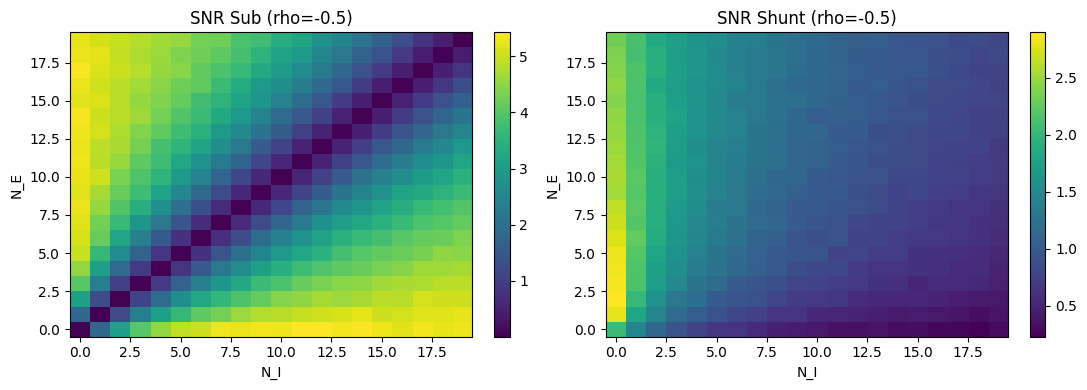

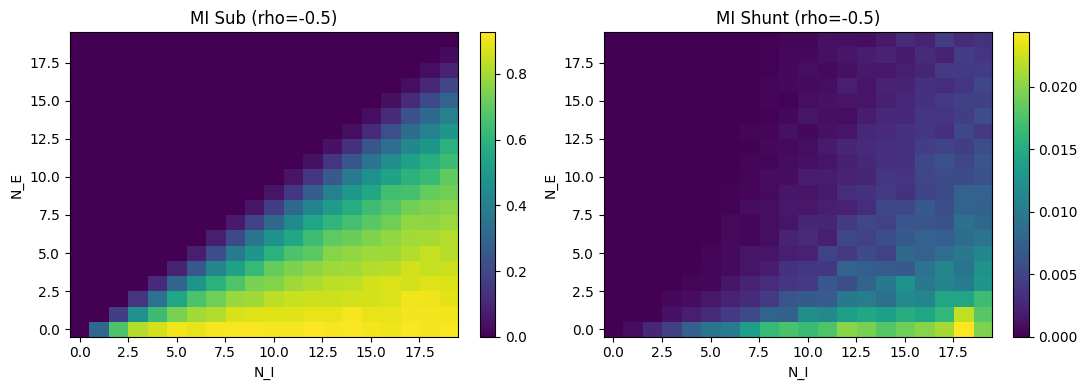

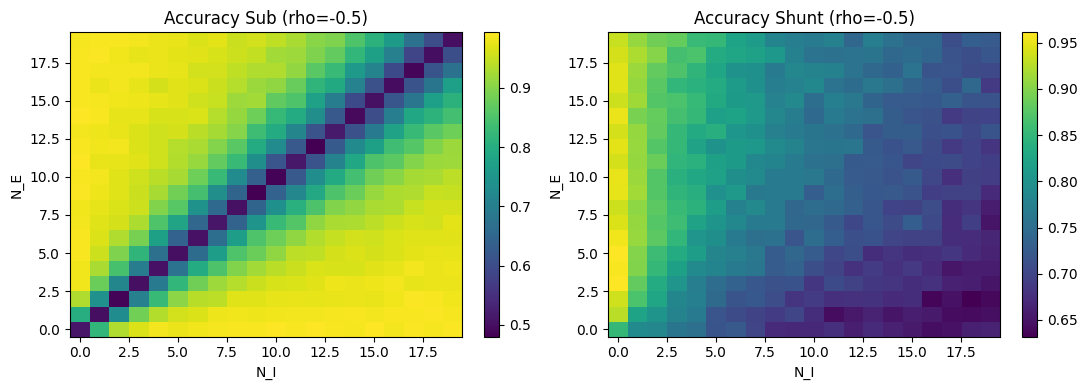

=== Running correlation=0.00 ===


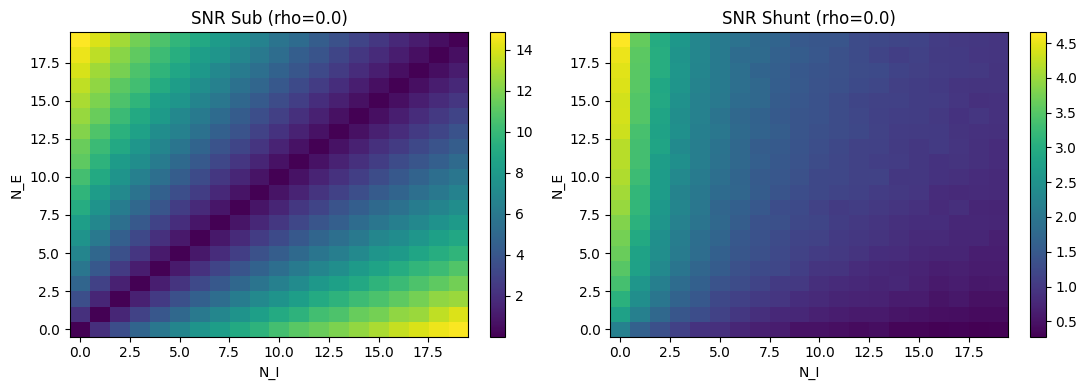

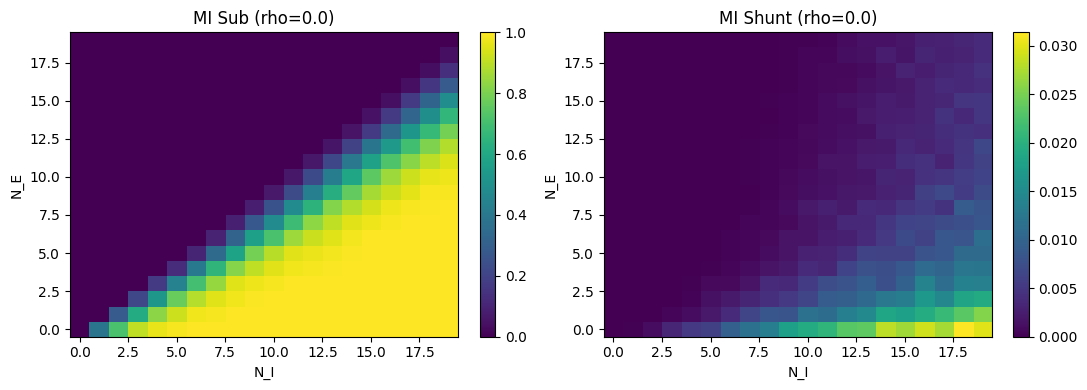

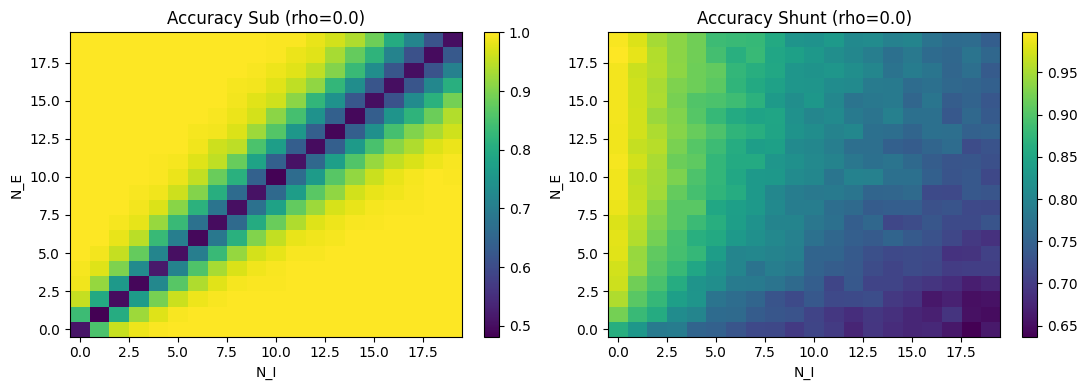

=== Running correlation=0.30 ===


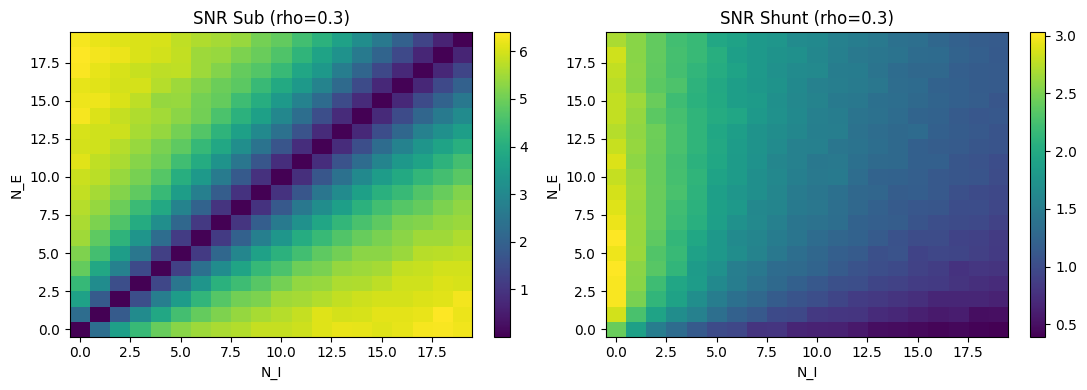

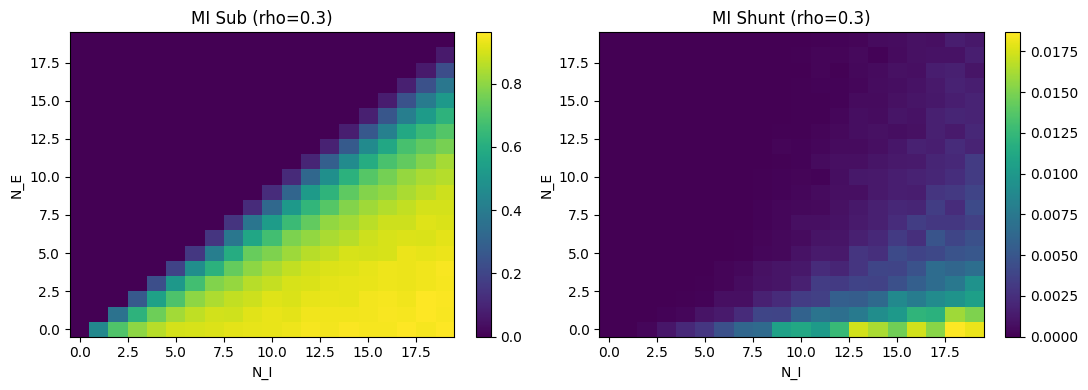

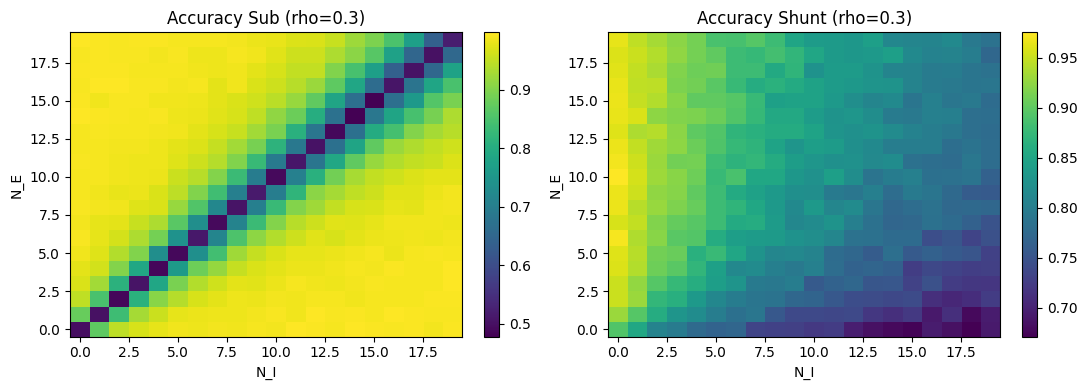

=== Running correlation=0.70 ===


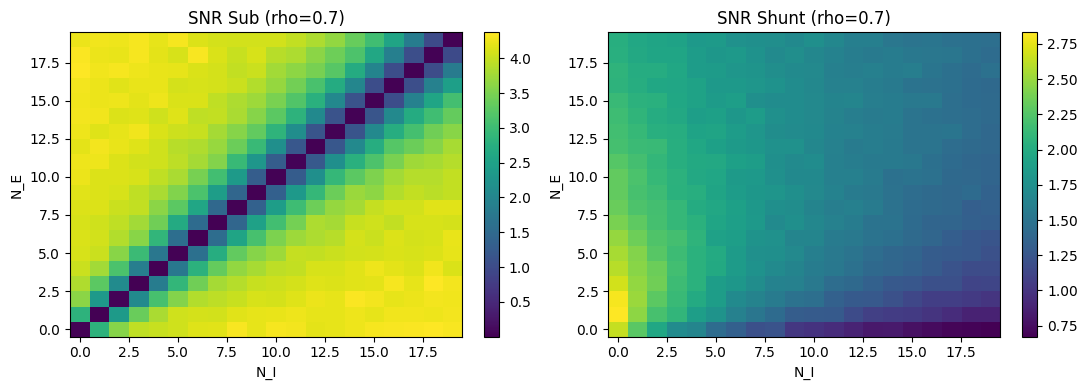

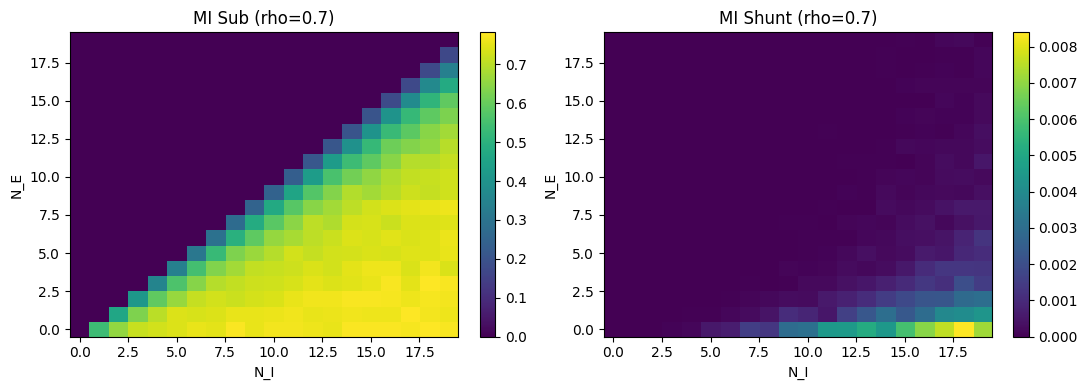

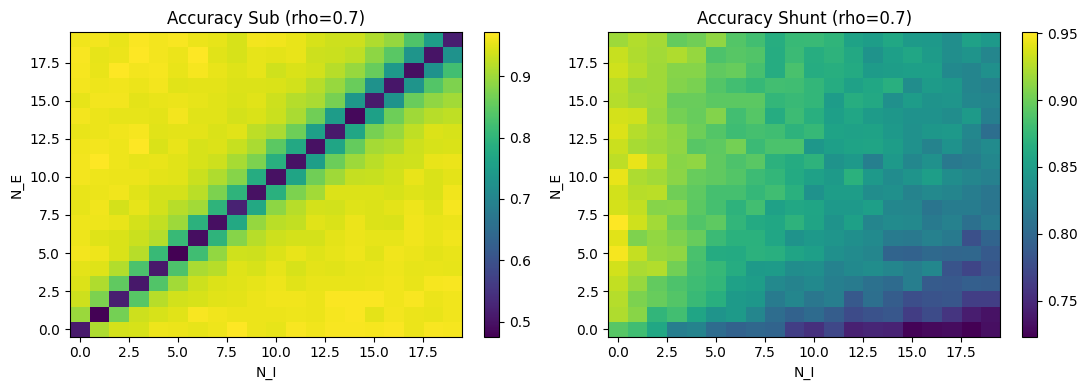

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

def sigmoid(x):
    return 1.0/(1.0 + np.exp(-x))

def generate_correlated_gaussian(n_samples, d, mean1, mean2, rho):
    """
    Creates data for 2 classes in dimension d:
      Covariance: diag=1, off-diag=rho
      half labeled class=1, half class=2.
    """
    Sigma = np.full((d,d), rho)
    np.fill_diagonal(Sigma, 1.0)
    half = n_samples//2
    X1 = np.random.multivariate_normal(mean1, Sigma, size=half)
    X2 = np.random.multivariate_normal(mean2, Sigma, size=half)
    X = np.vstack([X1, X2])
    y = np.hstack([np.ones(half), 2*np.ones(half)])
    return X, y

def find_min_error_threshold(vals, labels):
    """
    For 1D 'vals' with binary labels {1,2}, find threshold T that min. classification error.
    Return (best_T, best_err).
    """
    idx = np.argsort(vals)
    sorted_vals = vals[idx]
    sorted_labels = labels[idx]

    n1 = np.sum(labels==1)
    n2 = np.sum(labels==2)
    c1_left = 0
    c2_left = 0
    best_err=1.0
    best_T  = 0.5*(sorted_vals[0]+sorted_vals[-1])

    for i in range(len(vals)-1):
        if sorted_labels[i]==1:
            c1_left+=1
        else:
            c2_left+=1
        T = 0.5*(sorted_vals[i]+sorted_vals[i+1])
        frac_c2_left  = c2_left/n2
        frac_c1_right = (n1-c1_left)/n1
        err = 0.5*(frac_c2_left+frac_c1_right)
        if err<best_err:
            best_err=err
            best_T=T
    return best_T,best_err

def binary_entropy_bits(p):
    if p<=0 or p>=1:
        return 0.0
    return -p*np.log2(p) - (1-p)*np.log2(1-p)

def measure_snr_mi(vals, labels):
    """
    1) SNR = mean_diff / sqrt(pooled_var)
    2) MI in [0,1]: from minimal error classification => 1 - H_b(err)
    """
    v1 = vals[labels==1]
    v2 = vals[labels==2]
    m1 = v1.mean(); m2=v2.mean()
    var1=v1.var(ddof=1); var2=v2.var(ddof=1)
    mean_diff = np.abs(m1-m2)
    pooled_var=0.5*(var1+var2)
    if pooled_var<1e-14:
        snr=0.0
    else:
        snr=mean_diff/np.sqrt(pooled_var)
    # MI
    T, err = find_min_error_threshold(vals, labels)
    mi = 1.0 - binary_entropy_bits(err)
    return snr, mi

def measure_classifier_accuracy(vals, labels):
    """
    Fit logistic regression on single dimension 'vals' => label {1,2}.
    Return test accuracy. We'll map {1->0, 2->1}.
    """
    bin_labels = (labels==2).astype(int)
    X_1d = vals.reshape(-1,1)
    X_tr, X_te, y_tr, y_te = train_test_split(X_1d, bin_labels,
                                             test_size=0.2, random_state=42)
    clf = LogisticRegression()
    clf.fit(X_tr, y_tr)
    acc = clf.score(X_te, y_te)
    return acc

def run_NE_NI_sweep(maxN=20, n_samples=10000,
                    mu_diff=1.5, rho=0.3,
                    wE=1.0, wI=1.0):
    """
    Sweep NE=1..maxN, NI=1..maxN => dimension=NE+NI
    Return 6 arrays: SNR_sub, MI_sub, ACC_sub, SNR_sh, MI_sh, ACC_sh
    """
    SNR_sub = np.zeros((maxN,maxN))
    MI_sub  = np.zeros((maxN,maxN))
    ACC_sub = np.zeros((maxN,maxN))

    SNR_sh = np.zeros((maxN,maxN))
    MI_sh  = np.zeros((maxN,maxN))
    ACC_sh = np.zeros((maxN,maxN))

    for NE in range(1,maxN+1):
        for NI in range(1,maxN+1):
            d = NE+NI
            mean1 = mu_diff*np.ones(d)
            mean2 = -mu_diff*np.ones(d)
            X,y = generate_correlated_gaussian(n_samples, d, mean1, mean2, rho)

            Xsig = sigmoid(X)
            E = wE*np.sum(Xsig[:,:NE], axis=1) if NE>0 else 0.0
            I = wI*np.sum(Xsig[:,NE:], axis=1) if NI>0 else 0.0

            # Subtractive
            v_sub = E - I
            snr_sub, mi_sub = measure_snr_mi(v_sub, y)
            acc_sub = measure_classifier_accuracy(v_sub, y)
            SNR_sub[NE-1,NI-1]=snr_sub
            MI_sub[NE-1,NI-1] =mi_sub
            ACC_sub[NE-1,NI-1]=acc_sub

            # Shunting
            eps=1e-12
            v_sh = E/(1+E+I+eps)
            snr_sh, mi_sh = measure_snr_mi(v_sh, y)
            acc_sh = measure_classifier_accuracy(v_sh, y)
            SNR_sh[NE-1,NI-1]=snr_sh
            MI_sh[NE-1,NI-1]=mi_sh
            ACC_sh[NE-1,NI-1]=acc_sh

    return SNR_sub, MI_sub, ACC_sub, SNR_sh, MI_sh, ACC_sh

def plot_colormaps(data_sub, data_sh, title_sub, title_sh):
    """
    data_sub, data_sh shape=(maxN,maxN).
    No unify color scale => separate colorbars for clarity.
    """
    fig, axes = plt.subplots(1,2, figsize=(11,4))
    im0 = axes[0].imshow(data_sub, origin='lower', aspect='auto')
    plt.colorbar(im0, ax=axes[0], fraction=0.046)
    axes[0].set_title(title_sub)
    axes[0].set_xlabel('N_I')
    axes[0].set_ylabel('N_E')

    im1 = axes[1].imshow(data_sh, origin='lower', aspect='auto')
    plt.colorbar(im1, ax=axes[1], fraction=0.046)
    axes[1].set_title(title_sh)
    axes[1].set_xlabel('N_I')
    axes[1].set_ylabel('N_E')

    plt.tight_layout()
    plt.show()

def main():
    # multiple correlation levels
    correlation_list = [-0.5, 0.0, 0.3, 0.7]  # e.g. negative => "information enhancing"? or so
    maxN = 20
    n_samples = 8000
    mu_diff = 1.5
    wE, wI = 1.0, 1.0

    for rho in correlation_list:
        print("=== Running correlation=%.2f ==="%rho)
        (SNR_sub, MI_sub, ACC_sub,
         SNR_sh, MI_sh, ACC_sh) = run_NE_NI_sweep(maxN=maxN,
                                                  n_samples=n_samples,
                                                  mu_diff=mu_diff,
                                                  rho=rho,
                                                  wE=wE, wI=wI)
        # produce 3 windows for each correlation
        # 1) SNR
        plot_colormaps(SNR_sub, SNR_sh,
                       f'SNR Sub (rho={rho})',
                       f'SNR Shunt (rho={rho})')
        # 2) MI
        plot_colormaps(MI_sub, MI_sh,
                       f'MI Sub (rho={rho})',
                       f'MI Shunt (rho={rho})')
        # 3) Accuracy
        plot_colormaps(ACC_sub, ACC_sh,
                       f'Accuracy Sub (rho={rho})',
                       f'Accuracy Shunt (rho={rho})')

if __name__=="__main__":
    main()